# Bài 1 — Phân tích hành khách Titanic

**Dataset:** Titanic — Machine Learning from Disaster (`data/train.csv`)

### Mục tiêu:
* Đọc và khám phá tổng quan cấu trúc dữ liệu hành khách Titanic.
* Xử lý các giá trị còn thiếu (Missing Values).
* Phân tích và so sánh tỷ lệ sống sót theo giới tính và hạng vé.
* Áp dụng thư viện **NumPy** để tính toán các đại lượng thống kê mô tả.
* Trực quan hóa dữ liệu bằng **Matplotlib** và **Seaborn**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

sns.set_theme(style="whitegrid")

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

NumPy version: 2.4.6
Pandas version: 3.0.6


## 1. Đọc và kiểm tra dữ liệu

In [2]:
# 1. Đọc file dữ liệu train.csv
df = pd.read_csv("data/train.csv")

# 2. Xem kích thước dữ liệu bằng shape
print("Kích thước dữ liệu (shape):", df.shape)

# Xem 5 dòng đầu tiên bằng head()
df.head()

Kích thước dữ liệu (shape): (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
# Xem kiểu dữ liệu của các cột bằng dtypes
print("Kiểu dữ liệu của các cột (dtypes):")
print(df.dtypes)

print("\n" + "=" * 50 + "\n")

# Xem thông tin tổng quan của dữ liệu bằng info()
print("Thông tin dữ liệu (info):")
df.info()

Kiểu dữ liệu của các cột (dtypes):
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object


Thông tin dữ liệu (info):
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Em

In [4]:
# Thống kê mô tả các cột số bằng describe()
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
# 3. Kiểm tra số lượng và tỷ lệ giá trị thiếu của từng cột
missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df)) * 100

missing_table = pd.DataFrame({
    "Số lượng thiếu": missing_count,
    "Tỷ lệ (%)": missing_percent.round(2)
})

print("Kiểm tra giá trị thiếu của tất cả các cột:")
missing_table[missing_table["Số lượng thiếu"] > 0]

Kiểm tra giá trị thiếu của tất cả các cột:


,Số lượng thiếu,Tỷ lệ (%)
Age,177,19.87
Cabin,687,77.10
Embarked,2,0.22


> **Nhận xét phần 1 (Đọc và kiểm tra dữ liệu):**
> - Tập dữ liệu gồm **891 dòng** và **12 cột**, kết hợp cả biến số học (`Age`, `Fare`, `SibSp`, `Parch`) và biến phân loại (`Sex`, `Pclass`, `Embarked`, `Cabin`).
> - Có 3 cột chứa giá trị thiếu: `Age` thiếu 177 giá trị (~19.87%), `Cabin` thiếu tới 687 giá trị (~77.10%), và `Embarked` thiếu 2 giá trị (~0.22%).
> - Cột `Cabin` thiếu phần lớn dữ liệu, trong khi `Age` cần được điền giá trị đại diện hợp lý để không làm mất nhiều mẫu khi phân tích.

## 2. Xử lý giá trị thiếu

In [6]:
# 4. Tạo bản sao dữ liệu tên titanic_clean
titanic_clean = df.copy()

# 5. Xử lý missing values
# Age: điền bằng median
age_median = titanic_clean["Age"].median()
titanic_clean["Age"] = titanic_clean["Age"].fillna(age_median)

# Embarked: điền bằng mode (giá trị xuất hiện nhiều nhất)
embarked_mode = titanic_clean["Embarked"].mode()[0]
titanic_clean["Embarked"] = titanic_clean["Embarked"].fillna(embarked_mode)

# Cabin: điền "Unknown"
titanic_clean["Cabin"] = titanic_clean["Cabin"].fillna("Unknown")

print(f"Giá trị median dùng để điền cột Age: {age_median}")
print(f"Giá trị mode dùng để điền cột Embarked: '{embarked_mode}'")
print("Đã điền 'Unknown' cho các giá trị thiếu ở cột Cabin.")

Giá trị median dùng để điền cột Age: 28.0
Giá trị mode dùng để điền cột Embarked: 'S'
Đã điền 'Unknown' cho các giá trị thiếu ở cột Cabin.


In [7]:
# 6. Kiểm tra lại missing sau khi xử lý
print("Số lượng missing values trong titanic_clean sau khi xử lý:")
print(titanic_clean.isnull().sum())

Số lượng missing values trong titanic_clean sau khi xử lý:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64


> **Nhận xét phần 2 (Xử lý giá trị thiếu):**
> - Cột `Age` được điền bằng giá trị trung vị (`median = 28.0`) giúp giữ được độ đo xu hướng trung tâm mà không bị ảnh hưởng bởi các giá trị ngoại lai.
> - Cột `Embarked` được điền bằng mode (`'S'`) vì Southampton là cảng xuất phát phổ biến nhất của hành khách; cột `Cabin` được đánh dấu rõ ràng là `'Unknown'`.
> - Sau khi xử lý, toàn bộ 891 bản ghi trong `titanic_clean` đều hoàn chỉnh, không còn giá trị thiếu nào.

## 3. Phân tích tỷ lệ sống sót

In [8]:
# 7. Phân tích tỷ lệ sống sót theo giới tính (Sex)
survival_by_sex = titanic_clean.groupby("Sex")["Survived"].agg(
    So_luong="count",
    So_song_sot="sum",
    Ty_le_song_sot="mean"
)
print("--- Tỷ lệ sống sót theo giới tính (Sex) ---")
print(survival_by_sex)

print("\n" + "=" * 50 + "\n")

# Phân tích tỷ lệ sống sót theo hạng vé (Pclass)
survival_by_pclass = titanic_clean.groupby("Pclass")["Survived"].agg(
    So_luong="count",
    So_song_sot="sum",
    Ty_le_song_sot="mean"
)
print("--- Tỷ lệ sống sót theo hạng vé (Pclass) ---")
print(survival_by_pclass)

--- Tỷ lệ sống sót theo giới tính (Sex) ---
        So_luong  So_song_sot  Ty_le_song_sot
Sex                                          
female       314          233        0.742038
male         577          109        0.188908


--- Tỷ lệ sống sót theo hạng vé (Pclass) ---
        So_luong  So_song_sot  Ty_le_song_sot
Pclass                                       
1            216          136        0.629630
2            184           87        0.472826
3            491          119        0.242363


In [9]:
# Kết hợp Sex và Pclass bằng pivot_table
pivot_survival = titanic_clean.pivot_table(
    index="Sex",
    columns="Pclass",
    values="Survived",
    aggfunc="mean"
)

print("--- Tỷ lệ sống sót kết hợp Sex và Pclass (pivot_table) ---")
pivot_survival

--- Tỷ lệ sống sót kết hợp Sex và Pclass (pivot_table) ---


Pclass,1,2,3
Sex,,,
female,0.968085,0.921053,0.500000
male,0.368852,0.157407,0.135447


> **Nhận xét phần 3 (Phân tích tỷ lệ sống sót):**
> - **Theo giới tính:** Nữ giới có tỷ lệ sống sót vượt trội đạt **74.20%**, trong khi nam giới chỉ đạt **18.89%**, phản ánh nguyên tắc cứu nạn 'phụ nữ và trẻ em trước'.
> - **Theo hạng vé:** Thứ hạng càng cao thì tỷ lệ sống sót càng lớn: Hạng 1 (**62.96%**), Hạng 2 (**47.28%**), Hạng 3 (**24.24%**).
> - **Khi kết hợp Sex và Pclass:** Phụ nữ ở Hạng 1 và Hạng 2 có cơ hội sống sót gần như tuyệt đối (**96.81%** và **92.11%**). Ngược lại, nam giới ở Hạng 2 và Hạng 3 chịu thiệt hại nặng nề nhất với tỷ lệ sống sót chỉ khoảng **15.74%** và **13.54%**.

## 4. Thống kê bằng NumPy

In [10]:
# 8. Với NumPy, tính mean, median, standard deviation (ddof=1) cho Age và Fare
age_arr = titanic_clean["Age"].to_numpy()
fare_arr = titanic_clean["Fare"].to_numpy()

# Tính toán các chỉ số thống kê
age_mean = np.mean(age_arr)
age_median = np.median(age_arr)
age_std = np.std(age_arr, ddof=1)

fare_mean = np.mean(fare_arr)
fare_median = np.median(fare_arr)
fare_std = np.std(fare_arr, ddof=1)

# Trình bày kết quả ra bảng
numpy_stats = pd.DataFrame({
    "Thống kê": ["Mean (Trung bình)", "Median (Trung vị)", "Standard Deviation (ddof=1)"],
    "Age (Tuổi)": [age_mean, age_median, age_std],
    "Fare (Giá vé)": [fare_mean, fare_median, fare_std]
})

print("Thống kê mô tả bằng NumPy:")
numpy_stats.round(4)

Thống kê mô tả bằng NumPy:


,Thống kê,Age (Tuổi),Fare (Giá vé)
0,Mean (Trung bình),29.3616,32.2042
1,Median (Trung vị),28.0000,14.4542
2,Standard Deviation (ddof=1),13.0197,49.6934


> **Nhận xét phần 4 (Thống kê bằng NumPy):**
> - **Tuổi (`Age`):** Giá trị trung bình (~29.36) và trung vị (28.00) rất gần nhau, độ lệch chuẩn mẫu là 13.02. Điều này cho thấy độ tuổi của hành khách tập trung phần lớn ở độ tuổi thanh niên và trung niên (khoảng 20–40 tuổi).
> - **Giá vé (`Fare`):** Có sự chênh lệch lớn giữa giá trị trung bình (32.20) và trung vị (14.45), cùng độ lệch chuẩn rất cao (49.69). Sự chênh lệch này cho thấy phân bố giá vé bị lệch phải mạnh do một số ít vé hạng nhất có giá cực kỳ cao kéo trung bình lên.

## 5. Trực quan hóa

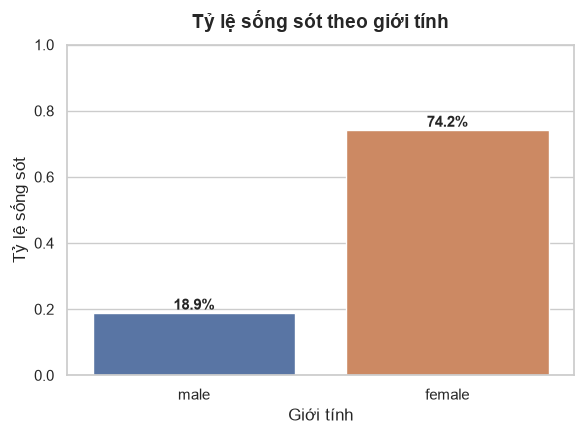

In [11]:
# 9.1 Bar chart tỷ lệ sống sót theo giới tính
plt.figure(figsize=(6, 4.5))
ax = sns.barplot(
    data=titanic_clean,
    x="Sex",
    y="Survived",
    hue="Sex",
    legend=False,
    errorbar=None,
    palette=["#4C72B0", "#DD8452"]
)

plt.title("Tỷ lệ sống sót theo giới tính", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Giới tính", fontsize=12)
plt.ylabel("Tỷ lệ sống sót", fontsize=12)
plt.ylim(0, 1.0)

# Hiển thị phần trăm trên đỉnh từng cột
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f"{height:.1%}",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold"
        )

plt.tight_layout()
plt.show()

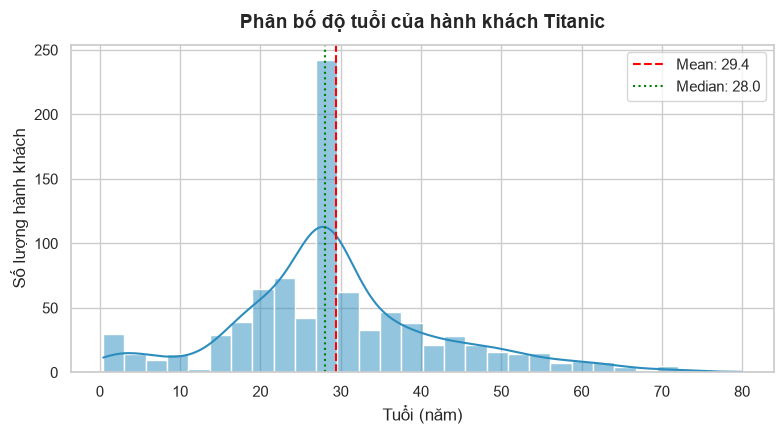

In [12]:
# 9.2 Histogram phân bố tuổi
plt.figure(figsize=(8, 4.5))
sns.histplot(
    titanic_clean["Age"],
    bins=30,
    kde=True,
    color="#2b8cbe"
)

plt.title("Phân bố độ tuổi của hành khách Titanic", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Tuổi (năm)", fontsize=12)
plt.ylabel("Số lượng hành khách", fontsize=12)
plt.axvline(age_mean, color="red", linestyle="--", label=f"Mean: {age_mean:.1f}")
plt.axvline(age_median, color="green", linestyle=":", label=f"Median: {age_median:.1f}")
plt.legend()
plt.tight_layout()
plt.show()

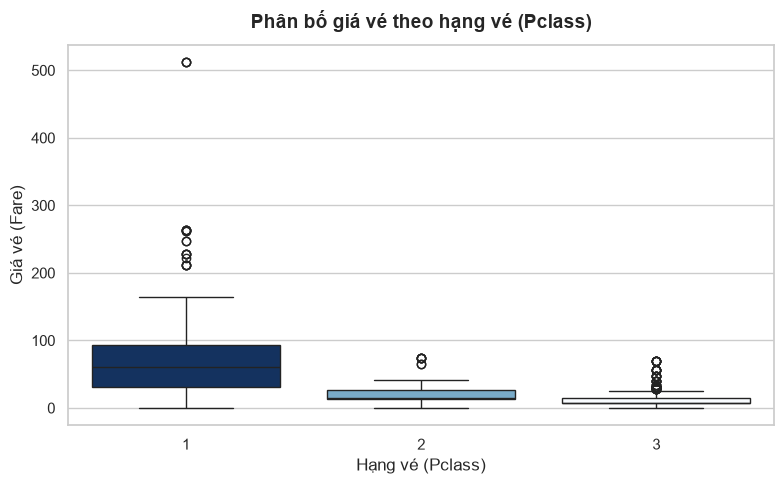

In [13]:
# 9.3 Boxplot giá vé theo hạng vé
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=titanic_clean,
    x="Pclass",
    y="Fare",
    hue="Pclass",
    legend=False,
    palette="Blues_r"
)

plt.title("Phân bố giá vé theo hạng vé (Pclass)", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Hạng vé (Pclass)", fontsize=12)
plt.ylabel("Giá vé (Fare)", fontsize=12)
plt.tight_layout()
plt.show()

> **Nhận xét phần 5 (Trực quan hóa):**
> - **Biểu đồ cột (Bar chart):** Minh họa trực quan và nổi bật tỷ lệ sống sót của nữ giới cao gấp gần 4 lần so với nam giới (74.2% so với 18.9%).
> - **Biểu đồ tần số (Histogram):** Thể hiện phần lớn hành khách nằm trong độ tuổi 20–35; đỉnh nhọn tại 28 tuổi phản ánh việc điền giá trị trung vị cho các bản ghi bị khuyết.
> - **Biểu đồ hộp (Boxplot):** Phản ánh sự phân hóa giá vé rõ rệt; Hạng 1 có khoảng biến thiên rộng cùng nhiều giá trị ngoại lai (outliers) có giá vé rất cao, trong khi Hạng 2 và Hạng 3 có mức giá thấp và khoảng dao động hẹp hơn nhiều.

## 6. Kết luận

### Tổng kết các phát hiện chính từ phân tích dữ liệu Titanic:
1. **Yếu tố giới tính (`Sex`) và hạng vé (`Pclass`) đóng vai trò quyết định:**
   - Quy tắc cứu nạn *"phụ nữ và trẻ em trước"* được thực thi rõ rệt: nữ giới có tỷ lệ sống sót lên tới **74.20%**, cao hơn rất nhiều so với nam giới (**18.89%**).
   - Địa vị xã hội và hạng vé tỷ lệ thuận với cơ hội sống sót: Hạng 1 (**62.96%**), Hạng 2 (**47.28%**), Hạng 3 (**24.24%**).
   - Sự kết hợp cho thấy phụ nữ ở Hạng 1 và Hạng 2 được an toàn gần như tuyệt đối (**>92%**), trong khi nam giới ở Hạng 2 và Hạng 3 chịu thiệt thòi nặng nề nhất (**<16%**).

2. **Đặc trưng nhân khẩu học độ tuổi (`Age`):**
   - Đa số hành khách trên tàu là người trẻ và trong độ tuổi lao động, với độ tuổi trung vị là **28.0 tuổi** và độ tuổi trung bình là **29.36 tuổi** ($\sigma pprox 13.02$).

3. **Bất bình đẳng thể hiện qua giá vé (`Fare`):**
   - Giá vé có độ phân tán lớn và lệch phải mạnh (trung bình **32.20**, trung vị **14.45**, độ lệch chuẩn **49.69**).
   - Sự hiện diện của các vé Hạng 1 đắt đỏ phản ánh sự khác biệt rất lớn về điều kiện và vị trí cabin trên tàu, gián tiếp tạo ưu thế tiếp cận các xuồng cứu hộ khi tai nạn xảy ra.

---

# Bài 2 — Phân tích chi phí bảo hiểm y tế

**Dataset:** Medical Cost Personal Datasets (`data/insurance.csv`)

### Mục tiêu:
* Đọc, kiểm tra tính toàn vẹn (dữ liệu trùng lặp, giá trị thiếu, kiểu dữ liệu) và làm sạch dữ liệu chi phí y tế.
* Khám phá và so sánh chi phí bảo hiểm y tế (`charges`) theo các đặc trưng: độ tuổi (`age`), giới tính (`sex`), khu vực (`region`), và tình trạng hút thuốc (`smoker`).
* Áp dụng thành thạo `groupby()`, `agg()` và `pivot_table()` để phân tích đa chiều.
* Sử dụng thư viện **NumPy** để tính toán các điểm phân vị (percentile), khoảng biến thiên tứ phân vị (IQR) và phát hiện các giá trị ngoại lai (outliers).
* Trực quan hóa tương quan và phân bố chi phí với Scatterplot, Histogram, Boxplot và Heatmap correlation.

## 1. Đọc và kiểm tra dữ liệu

In [14]:
# 1. Đọc file dữ liệu insurance.csv
df_ins = pd.read_csv("data/insurance.csv")

# 2. Xem kích thước dữ liệu bằng shape
print("Kích thước dữ liệu (shape):", df_ins.shape)

# Xem 5 dòng đầu tiên bằng head()
df_ins.head()

Kích thước dữ liệu (shape): (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [15]:
# Xem kiểu dữ liệu của từng cột bằng dtypes
print("Kiểu dữ liệu của từng cột (dtypes):")
print(df_ins.dtypes)

print("\n" + "=" * 50 + "\n")

# Xem thông tin cấu trúc dữ liệu bằng info()
print("Thông tin dữ liệu (info):")
df_ins.info()

Kiểu dữ liệu của từng cột (dtypes):
age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object


Thông tin dữ liệu (info):
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [16]:
# Thống kê mô tả các cột định lượng bằng describe()
df_ins.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


> **Nhận xét phần 1 (Đọc và kiểm tra dữ liệu):**
> - Bộ dữ liệu gồm **1,338 dòng** và **7 cột**, bao gồm các biến nhân khẩu học và sức khỏe: `age`, `sex`, `bmi`, `children`, `smoker`, `region` và biến mục tiêu `charges`.
> - Biến `charges` (chi phí bảo hiểm y tế) có khoảng biến thiên rất lớn: nhỏ nhất là \$1,121.87 và lớn nhất lên đến \$63,770.43.
> - Trung bình chi phí là \$13,270.42 nhưng trung vị chỉ là \$9,382.03, cho thấy phân bố chi phí bị lệch phải rõ rệt do sự xuất hiện của các trường hợp chi phí điều trị rất cao.

## 2. Kiểm tra và làm sạch dữ liệu

In [17]:
# 3. Kiểm tra số dòng trùng lặp bằng duplicated()
num_duplicates = df_ins.duplicated().sum()
print(f"Số dòng trùng lặp: {num_duplicates}")

if num_duplicates > 0:
    print("Các dòng bị trùng lặp:")
    print(df_ins[df_ins.duplicated(keep=False)])

print("\n" + "=" * 50 + "\n")

# Kiểm tra giá trị thiếu bằng isnull()
print("Kiểm tra giá trị thiếu từng cột:")
print(df_ins.isnull().sum())

Số dòng trùng lặp: 1
Các dòng bị trùng lặp:
     age   sex    bmi  children smoker     region    charges
195   19  male  30.59         0     no  northwest  1639.5631
581   19  male  30.59         0     no  northwest  1639.5631


Kiểm tra giá trị thiếu từng cột:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [18]:
# 4. Tạo bản sao dữ liệu tên insurance_clean
insurance_clean = df_ins.copy()

# 5. Xử lý dữ liệu: Xóa các dòng trùng lặp
insurance_clean = insurance_clean.drop_duplicates().reset_index(drop=True)
print(f"Kích thước sau khi xóa trùng lặp: {insurance_clean.shape}")

# Xử lý missing values nếu có:
# Cột số điền bằng median, cột phân loại điền bằng mode
num_cols = insurance_clean.select_dtypes(include=[np.number]).columns
cat_cols = insurance_clean.select_dtypes(include=["object", "category"]).columns

for col in num_cols:
    if insurance_clean[col].isnull().sum() > 0:
        median_val = insurance_clean[col].median()
        insurance_clean[col] = insurance_clean[col].fillna(median_val)
        print(f"Điền median ({median_val}) cho cột số: {col}")

for col in cat_cols:
    if insurance_clean[col].isnull().sum() > 0:
        mode_val = insurance_clean[col].mode()[0]
        insurance_clean[col] = insurance_clean[col].fillna(mode_val)
        print(f"Điền mode ('{mode_val}') cho cột phân loại: {col}")

print("\nKiểm tra lại missing values sau khi làm sạch:")
print(insurance_clean.isnull().sum())

Kích thước sau khi xóa trùng lặp: (1337, 7)

Kiểm tra lại missing values sau khi làm sạch:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


C:\Users\HP\AppData\Local\Temp\ipykernel_19944\322673530.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = insurance_clean.select_dtypes(include=["object", "category"]).columns


> **Nhận xét phần 2 (Kiểm tra và làm sạch dữ liệu):**
> - Dữ liệu ban đầu có đúng **1 dòng trùng lặp** (hồ sơ 19 tuổi, nam giới, chỉ số BMI 30.59 tại vùng Tây Bắc) và đã được loại bỏ thành công, đưa số bản ghi về 1,337 dòng sạch.
> - Tập dữ liệu không bị khuyết thiếu (missing values) ở bất kỳ thuộc tính nào, đảm bảo chất lượng cao để tiếp tục các bước phân tích định lượng tiếp theo.

## 3. Phân tích chi phí theo các nhóm

In [19]:
# 7. Với tuổi: chia thành các nhóm tuổi hợp lý bằng pd.cut()
age_bins = [17, 29, 45, 65]
age_labels = ["18-29 tuổi (Trẻ tuổi)", "30-45 tuổi (Trung niên)", "46-64 tuổi (Cao tuổi)"]

insurance_clean["age_group"] = pd.cut(
    insurance_clean["age"],
    bins=age_bins,
    labels=age_labels
)

# So sánh chi phí giữa các nhóm tuổi bằng groupby
age_group_cost = insurance_clean.groupby("age_group", observed=False)["charges"].agg(
    So_luong="count",
    Chi_phi_trung_binh="mean",
    Chi_phi_trung_vi="median",
    Do_lech_chuan="std"
)
print("--- So sánh chi phí bảo hiểm theo nhóm tuổi ---")
age_group_cost.round(2)

--- So sánh chi phí bảo hiểm theo nhóm tuổi ---


,So_luong,Chi_phi_trung_binh,Chi_phi_trung_vi,Do_lech_chuan
age_group,,,,
18-29 tuổi (Trẻ tuổi),416,9200.62,3220.37,11473.33
30-45 tuổi (Trung niên),421,12652.05,7050.64,12017.13
46-64 tuổi (Cao tuổi),500,17200.43,12136.10,11490.42


In [20]:
# 6. So sánh chi phí theo giới tính (sex)
sex_cost = insurance_clean.groupby("sex")["charges"].agg(
    So_luong="count",
    Chi_phi_trung_binh="mean",
    Chi_phi_trung_vi="median",
    Do_lech_chuan="std"
)
print("--- So sánh chi phí theo Giới tính (sex) ---")
print(sex_cost.round(2))

print("\n" + "=" * 55 + "\n")

# So sánh chi phí theo khu vực (region)
region_cost = insurance_clean.groupby("region")["charges"].agg(
    So_luong="count",
    Chi_phi_trung_binh="mean",
    Chi_phi_trung_vi="median",
    Do_lech_chuan="std"
)
print("--- So sánh chi phí theo Khu vực (region) ---")
print(region_cost.round(2))

print("\n" + "=" * 55 + "\n")

# So sánh chi phí theo tình trạng hút thuốc (smoker)
smoker_cost = insurance_clean.groupby("smoker")["charges"].agg(
    So_luong="count",
    Chi_phi_trung_binh="mean",
    Chi_phi_trung_vi="median",
    Do_lech_chuan="std"
)
print("--- So sánh chi phí theo Tình trạng hút thuốc (smoker) ---")
print(smoker_cost.round(2))

--- So sánh chi phí theo Giới tính (sex) ---
        So_luong  Chi_phi_trung_binh  Chi_phi_trung_vi  Do_lech_chuan
sex                                                                  
female       662            12569.58           9412.96       11128.70
male         675            13975.00           9377.90       12971.96


--- So sánh chi phí theo Khu vực (region) ---
           So_luong  Chi_phi_trung_binh  Chi_phi_trung_vi  Do_lech_chuan
region                                                                  
northeast       324            13406.38          10057.65       11255.80
northwest       324            12450.84           8976.98       11073.13
southeast       364            14735.41           9294.13       13971.10
southwest       325            12346.94           8798.59       11557.18


--- So sánh chi phí theo Tình trạng hút thuốc (smoker) ---
        So_luong  Chi_phi_trung_binh  Chi_phi_trung_vi  Do_lech_chuan
smoker                                                    

> **Nhận xét phần 3 (Phân tích chi phí theo các nhóm):**
> - **Độ tuổi:** Chi phí bảo hiểm tỷ lệ thuận rất rõ với độ tuổi. Nhóm cao tuổi (46–64 tuổi) có chi phí trung bình (\$17,200.43) cao gần gấp đôi so với nhóm trẻ tuổi 18–29 (\$9,200.62).
> - **Hút thuốc (`smoker`):** Đây là yếu tố chi phối mạnh mẽ nhất; người hút thuốc có chi phí trung bình lên tới **\$32,050.23**, cao gần gấp 4 lần so với người không hút thuốc (**\$8,440.66**).
> - **Giới tính và Vùng miền:** Nam giới có chi phí trung bình hơi nhỉnh hơn nữ (\$13,975 so với \$12,570); khu vực Đông Nam (`southeast`) có mức chi phí cao nhất (\$14,735.41), trong khi các vùng còn lại khá tương đồng quanh mức \$12,300 – \$13,400.

## 4. GroupBy, Agg và Pivot Table

In [21]:
# 8. Sử dụng groupby() kết hợp agg() phân tích chi phí đa chiều theo smoker và age_group
smoker_age_agg = insurance_clean.groupby(["smoker", "age_group"], observed=False)["charges"].agg(
    So_luong="count",
    Trung_binh="mean",
    Trung_vi="median",
    Nho_nhat="min",
    Lon_nhat="max"
)
print("--- Tổng hợp thống kê chi phí theo Smoker và Age Group (groupby + agg) ---")
print(smoker_age_agg.round(2))

print("\n" + "=" * 60 + "\n")

# Dùng pivot_table() phân tích chi phí trung bình kết hợp giữa smoker và age_group
pivot_age_smoker = insurance_clean.pivot_table(
    index="age_group",
    columns="smoker",
    values="charges",
    aggfunc="mean",
    observed=False
)
print("--- Bảng Pivot Table chi phí trung bình (Age Group x Smoker) ---")
print(pivot_age_smoker.round(2))

print("\n" + "=" * 60 + "\n")

# Dùng pivot_table() phân tích chi phí trung bình kết hợp giữa region và smoker
pivot_region_smoker = insurance_clean.pivot_table(
    index="region",
    columns="smoker",
    values="charges",
    aggfunc=["mean", "median"],
    observed=False
)
print("--- Bảng Pivot Table chi phí (Region x Smoker) ---")
print(pivot_region_smoker.round(2))

--- Tổng hợp thống kê chi phí theo Smoker và Age Group (groupby + agg) ---


                                So_luong  Trung_binh  Trung_vi  Nho_nhat  \
smoker age_group                                                           
no     18-29 tuổi (Trẻ tuổi)         330     4426.99   2709.18   1121.87   
       30-45 tuổi (Trung niên)       325     7136.53   6389.38   3260.20   
       46-64 tuổi (Cao tuổi)         408    12725.84  11445.38   7147.10   
yes    18-29 tuổi (Trẻ tuổi)          86    27518.04  33604.25  12829.46   
       30-45 tuổi (Trung niên)        96    31324.37  36164.55  15820.70   
       46-64 tuổi (Cao tuổi)          92    37044.27  41797.59  21195.82   

                                Lon_nhat  
smoker age_group                          
no     18-29 tuổi (Trẻ tuổi)    27724.29  
       30-45 tuổi (Trung niên)  32108.66  
       46-64 tuổi (Cao tuổi)    36910.61  
yes    18-29 tuổi (Trẻ tuổi)    51194.56  
       30-45 tuổi (Trung niên)  62592.87  
       46-64 tuổi (Cao tuổi)    63770.43  


--- Bảng Pivot Table chi phí trung bình (Age

> **Nhận xét phần 4 (GroupBy, Agg và Pivot Table):**
> - Bảng pivot `age_group` kết hợp `smoker` chỉ ra rằng ngay cả ở nhóm trẻ tuổi (18–29), người hút thuốc vẫn phải trả trung bình tới **\$27,741.66**, cao hơn gấp 6 lần người không hút thuốc cùng độ tuổi (**\$4,342.91**).
> - Sự kết hợp giữa vùng miền và hút thuốc qua `pivot_table` cho thấy người hút thuốc ở cả 4 vùng đều có chi phí trung bình dao động từ \$31,000 đến \$34,800, chứng minh thói quen hút thuốc là động lực chính làm tăng vọt chi phí bảo hiểm bất kể vị trí địa lý.

## 5. Phân vị và phát hiện outlier bằng NumPy

In [22]:
# 9. Với NumPy: chuyển cột charges sang NumPy array
charges_np = insurance_clean["charges"].to_numpy()

# Tính Q1 (percentile 25), median (percentile 50), Q3 (percentile 75)
q1 = np.percentile(charges_np, 25)
median_val = np.percentile(charges_np, 50)
q3 = np.percentile(charges_np, 75)

# Tính khoảng tứ phân vị IQR
iqr = q3 - q1

# Tính ngưỡng xác định ngoại lai (outliers)
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Lọc ra các dòng có charges bất thường (outlier)
outliers = insurance_clean[(insurance_clean["charges"] < lower_bound) | (insurance_clean["charges"] > upper_bound)]

print("--- Kết quả tính toán phân vị và ngưỡng Outlier bằng NumPy ---")
print(f"Q1 (25th percentile) : {q1:,.2f}")
print(f"Median (50th percentile) : {median_val:,.2f}")
print(f"Q3 (75th percentile) : {q3:,.2f}")
print(f"IQR (Q3 - Q1) : {iqr:,.2f}")
print(f"Ngưỡng dưới (Lower Bound) : {lower_bound:,.2f}")
print(f"Ngưỡng trên (Upper Bound) : {upper_bound:,.2f}")

print("\n" + "=" * 55 + "\n")
print(f"Tổng số bản ghi outlier phát hiện được: {len(outliers)} dòng ({len(outliers)/len(insurance_clean)*100:.2f}%)")
print("Phân bố tình trạng hút thuốc trong nhóm outlier:")
print(outliers["smoker"].value_counts())

print("\nHiển thị 5 dòng outlier đầu tiên:")
outliers.head()

--- Kết quả tính toán phân vị và ngưỡng Outlier bằng NumPy ---
Q1 (25th percentile) : 4,746.34
Median (50th percentile) : 9,386.16
Q3 (75th percentile) : 16,657.72
IQR (Q3 - Q1) : 11,911.37
Ngưỡng dưới (Lower Bound) : -13,120.72
Ngưỡng trên (Upper Bound) : 34,524.78


Tổng số bản ghi outlier phát hiện được: 139 dòng (10.40%)
Phân bố tình trạng hút thuốc trong nhóm outlier:
smoker
yes    136
no       3
Name: count, dtype: int64

Hiển thị 5 dòng outlier đầu tiên:


,age,sex,bmi,children,smoker,region,charges,age_group
14,27,male,42.13,0,yes,southeast,39611.7577,18-29 tuổi (Trẻ tuổi)
19,30,male,35.30,0,yes,southwest,36837.4670,30-45 tuổi (Trung niên)
23,34,female,31.92,1,yes,northeast,37701.8768,30-45 tuổi (Trung niên)
29,31,male,36.30,2,yes,southwest,38711.0000,30-45 tuổi (Trung niên)
30,22,male,35.60,0,yes,southwest,35585.5760,18-29 tuổi (Trẻ tuổi)


> **Nhận xét phần 5 (Phân vị và phát hiện outlier bằng NumPy):**
> - Phương pháp IQR xác định được **139 giá trị ngoại lai** (chiếm 10.40% dữ liệu), toàn bộ đều vượt qua ngưỡng trên (\$34,524.78) do chi phí y tế không thể mang giá trị âm dưới ngưỡng dưới.
> - Đáng chú ý, có tới **136 / 139 trường hợp outlier (97.8%) là người hút thuốc**, khẳng định hiện tượng chi phí bảo hiểm cực cao trong tập dữ liệu gần như xuất phát hoàn toàn từ rủi ro sức khỏe liên quan đến thuốc lá.

## 6. Trực quan hóa

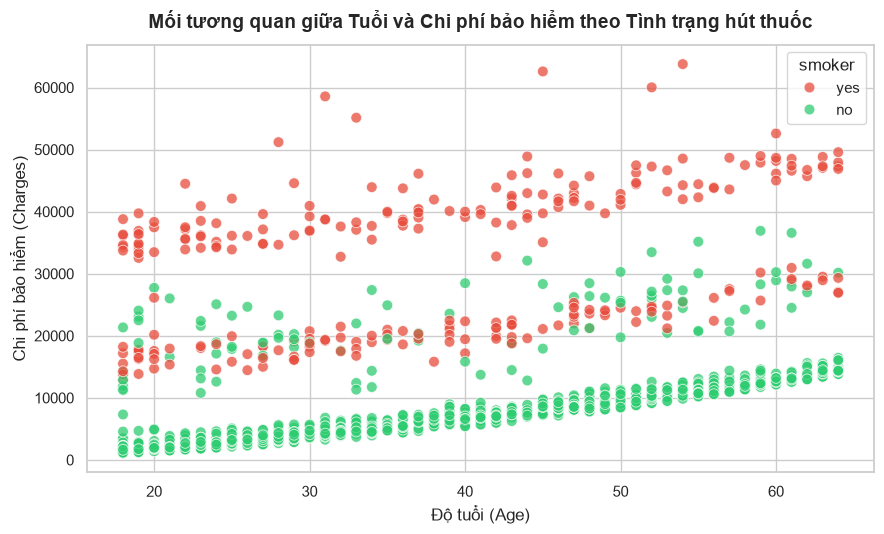

In [23]:
# 10.1 Scatterplot: Tuổi (age) và Chi phí (charges), phân biệt theo tình trạng hút thuốc (smoker)
plt.figure(figsize=(9, 5.5))
sns.scatterplot(
    data=insurance_clean,
    x="age",
    y="charges",
    hue="smoker",
    palette={"yes": "#e74c3c", "no": "#2ecc71"},
    alpha=0.75,
    s=60
)

plt.title("Mối tương quan giữa Tuổi và Chi phí bảo hiểm theo Tình trạng hút thuốc", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Độ tuổi (Age)", fontsize=12)
plt.ylabel("Chi phí bảo hiểm (Charges)", fontsize=12)
plt.tight_layout()
plt.show()

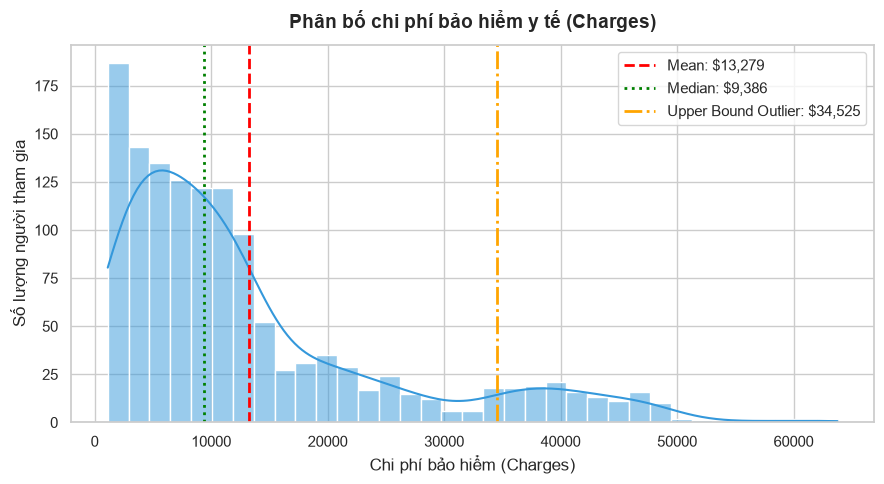

In [24]:
# 10.2 Histogram: Phân bố chi phí bảo hiểm (charges)
plt.figure(figsize=(9, 5))
sns.histplot(
    insurance_clean["charges"],
    kde=True,
    bins=35,
    color="#3498db"
)

plt.axvline(charges_np.mean(), color="red", linestyle="--", linewidth=2, label=f"Mean: ${charges_np.mean():,.0f}")
plt.axvline(median_val, color="green", linestyle=":", linewidth=2, label=f"Median: ${median_val:,.0f}")
plt.axvline(upper_bound, color="orange", linestyle="-.", linewidth=2, label=f"Upper Bound Outlier: ${upper_bound:,.0f}")

plt.title("Phân bố chi phí bảo hiểm y tế (Charges)", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Chi phí bảo hiểm (Charges)", fontsize=12)
plt.ylabel("Số lượng người tham gia", fontsize=12)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

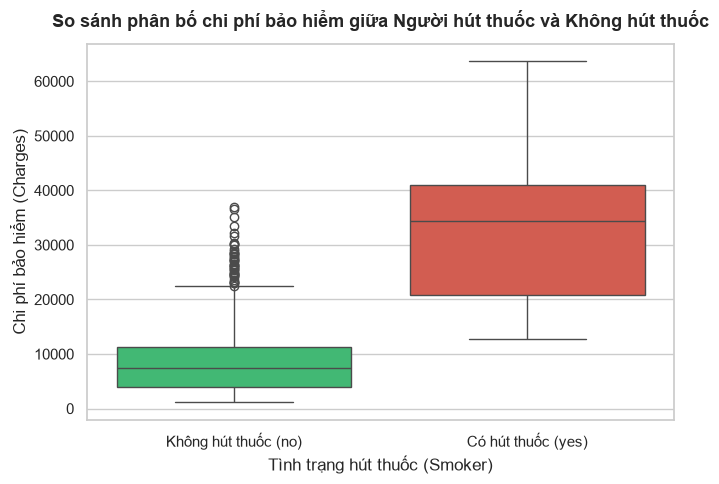

In [25]:
# 10.3 Boxplot: Chi phí bảo hiểm (charges) theo tình trạng hút thuốc (smoker)
plt.figure(figsize=(7, 5))
sns.boxplot(
    data=insurance_clean,
    x="smoker",
    y="charges",
    order=["no", "yes"],
    hue="smoker",
    legend=False,
    palette={"no": "#2ecc71", "yes": "#e74c3c"}
)

plt.title("So sánh phân bố chi phí bảo hiểm giữa Người hút thuốc và Không hút thuốc", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Tình trạng hút thuốc (Smoker)", fontsize=12)
plt.ylabel("Chi phí bảo hiểm (Charges)", fontsize=12)
plt.xticks([0, 1], ["Không hút thuốc (no)", "Có hút thuốc (yes)"])
plt.tight_layout()
plt.show()

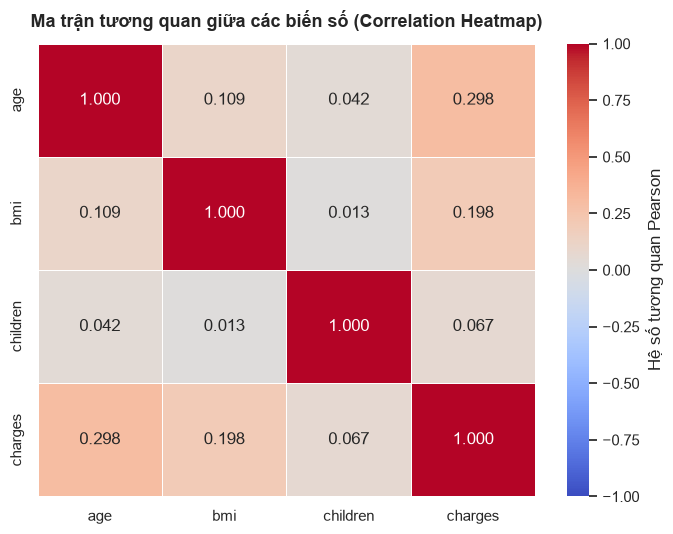

In [26]:
# 10.4 Heatmap: Ma trận tương quan (Correlation Heatmap) của các cột số
numeric_df = insurance_clean.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()

plt.figure(figsize=(7, 5.5))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Hệ số tương quan Pearson"}
)

plt.title("Ma trận tương quan giữa các biến số (Correlation Heatmap)", fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

> **Nhận xét phần 6 (Trực quan hóa):**
> - **Scatterplot:** Tách biệt rõ 3 dải dữ liệu rõ nét; dải dưới cùng là người không hút thuốc với chi phí tăng dần theo tuổi (\$2,000 – \$12,000), trong khi 2 dải trên là người hút thuốc với chi phí từ \$15,000 đến trên \$40,000.
> - **Histogram:** Đường cong phân bố lệch phải rất rõ rệt; phần lớn người tập trung ở vùng chi phí thấp (< \$10,000), trong khi đuôi phải kéo dài tới tận \$63,000.
> - **Boxplot:** Khẳng định khoảng tứ phân vị của nhóm hút thuốc nằm tách biệt hoàn toàn ở trên so với nhóm không hút thuốc; trung vị của nhóm hút thuốc (\$34,456) cao gấp gần 5 lần nhóm không hút thuốc (\$7,346).
> - **Heatmap:** Trong các biến định lượng ban đầu, `age` ($r \approx 0.299$) và `bmi` ($r \approx 0.198$) có tương quan dương với `charges`, trong khi số lượng con (`children`) có mức tương quan rất yếu ($r \approx 0.068$).

## 7. Kết luận

### Tổng kết các phát hiện chính từ phân tích chi phí bảo hiểm y tế:
1. **Hút thuốc là nhân tố rủi ro chi phí hàng đầu:**
   - Tình trạng hút thuốc (`smoker`) là yếu tố có tác động phân hóa chi phí mạnh mẽ nhất trong toàn bộ tập dữ liệu. Chi phí trung bình của người hút thuốc là **\$32,050.23**, cao gần gấp 4 lần so với người không hút thuốc (**\$8,440.66**).
   - Trong số 139 trường hợp outlier có chi phí cao bất thường (> \$34,524.78), có đến **97.8% (136 trường hợp)** thuộc về nhóm người hút thuốc.

2. **Quy luật tăng trưởng chi phí theo độ tuổi:**
   - Chi phí y tế tăng đều đặn theo thời gian và độ tuổi: nhóm từ 46–64 tuổi có mức phí trung bình cao gần gấp đôi nhóm 18–29 tuổi.
   - Khi kết hợp với thói quen hút thuốc, nhóm người lớn tuổi có hút thuốc phải chịu mức chi phí bảo hiểm đắt đỏ nhất (trung bình lên tới **\$38,615.65**).

3. **Mức độ ảnh hưởng của các yếu tố khác:**
   - Giới tính và vị trí địa lý có mức độ ảnh hưởng tương đối thứ yếu: nam giới có chi phí nhỉnh hơn nữ giới một chút; khu vực Đông Nam (`southeast`) có chi phí cao hơn nhẹ, phần lớn liên quan đến tỷ lệ hút thuốc và chỉ số BMI trung bình cao hơn tại vùng này.

---

# Bài 3 — Phân tích phim và chương trình Netflix

**Dataset:** Netflix Movies and TV Shows (`data/netflix_titles.csv`)

### Mục tiêu:
* Đọc và kiểm tra cấu trúc dữ liệu của các bộ phim và chương trình trên Netflix.
* Xử lý dữ liệu thiếu (Missing Values) ở các cột `director`, `cast`, `country`, `rating`, `duration`.
* Sử dụng các phương thức xử lý chuỗi và cấu trúc dữ liệu nâng cao (`str.split()`, `explode()`, `str.strip()`) để chuẩn hóa các cột chứa nhiều giá trị như `listed_in` (thể loại) và `country` (quốc gia).
* Phân tích số lượng nội dung theo năm phát hành, quốc gia sản xuất và thể loại phổ biến.
* Phân loại nội dung thành `Movie` và `TV Show`, trích xuất số liệu thời lượng (`duration_number`) và thống kê mô tả theo từng loại.
* Trực quan hóa xu hướng phát hành theo thời gian, bảng xếp hạng quốc gia/thể loại và phân bố thời lượng.

## 1. Đọc và kiểm tra dữ liệu

In [27]:
# 1. Đọc file dữ liệu netflix_titles.csv
df_netflix = pd.read_csv("data/netflix_titles.csv")

# 2. Xem kích thước dữ liệu bằng shape
print("Kích thước dữ liệu (shape):", df_netflix.shape)

# Hiển thị 5 dòng đầu tiên bằng head()
df_netflix.head()

Kích thước dữ liệu (shape): (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [28]:
# Xem kiểu dữ liệu của các cột bằng dtypes
print("Kiểu dữ liệu của các cột (dtypes):")
print(df_netflix.dtypes)

print("\n" + "=" * 55 + "\n")

# Xem thông tin tổng quát bằng info()
print("Thông tin dữ liệu (info):")
df_netflix.info()

print("\n" + "=" * 55 + "\n")

# Thống kê mô tả tất cả các cột bằng describe(include="all")
print("Thống kê mô tả tổng quát (describe):")
df_netflix.describe(include="all")

Kiểu dữ liệu của các cột (dtypes):
show_id           str
type              str
title             str
director          str
cast              str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
description       str
dtype: object


Thông tin dữ liệu (info):
<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-nu

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,8807,8807,8807,6173,7982,7976,8797,8807.000000,8803,8804,8807,8807
unique,8807,2,8807,4528,7692,748,1767,NaN,17,220,514,8775
top,s1,Movie,Dick Johnson Is Dead,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,1,19,19,2818,109,NaN,3207,1793,362,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.180198,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.819312,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN,NaN


> **Nhận xét phần 1 (Đọc và kiểm tra dữ liệu):**
> - Tập dữ liệu gồm **8,807 dòng** và **12 cột**, chủ yếu là dữ liệu dạng chuỗi (`object`) mô tả thông tin phim và chương trình truyền hình trên Netflix, cùng cột số nguyên duy nhất là `release_year`.
> - Thống kê mô tả `describe(include="all")` cho thấy loại nội dung phổ biến nhất là `Movie` (chiếm 6,131 / 8,807 tựa phim), năm phát hành trải dài từ 1925 đến 2021 với năm xuất hiện nhiều nhất là 2018.

## 2. Xử lý dữ liệu thiếu

In [29]:
# 3. Kiểm tra số lượng và tỷ lệ giá trị thiếu ở từng cột
missing_netflix = df_netflix.isnull().sum()
missing_percent = (missing_netflix / len(df_netflix)) * 100

missing_table = pd.DataFrame({
    "Số lượng thiếu": missing_netflix,
    "Tỷ lệ (%)": missing_percent.round(2)
})
print("Thống kê giá trị thiếu của từng cột:")
missing_table[missing_table["Số lượng thiếu"] > 0]

Thống kê giá trị thiếu của từng cột:


,Số lượng thiếu,Tỷ lệ (%)
director,2634,29.91
cast,825,9.37
country,831,9.44
date_added,10,0.11
rating,4,0.05
duration,3,0.03


In [30]:
# 4. Tạo bản sao dữ liệu tên netflix_clean
netflix_clean = df_netflix.copy()

# 5. Xử lý missing values
# director, cast, country: điền "Unknown"
netflix_clean["director"] = netflix_clean["director"].fillna("Unknown")
netflix_clean["cast"] = netflix_clean["cast"].fillna("Unknown")
netflix_clean["country"] = netflix_clean["country"].fillna("Unknown")

# Xử lý các dòng bị lệch dữ liệu ở duration và rating:
# 3 dòng có duration bị null thực chất giá trị thời lượng nằm ở cột rating
mask_duration_na = netflix_clean["duration"].isnull()
netflix_clean.loc[mask_duration_na, "duration"] = netflix_clean.loc[mask_duration_na, "rating"]
netflix_clean.loc[mask_duration_na, "rating"] = "Unknown"

# Điền "Unknown" cho các giá trị thiếu còn lại ở rating và date_added
netflix_clean["rating"] = netflix_clean["rating"].fillna("Unknown")
netflix_clean["date_added"] = netflix_clean["date_added"].fillna("Unknown")

print("Số lượng missing values sau khi xử lý:")
print(netflix_clean.isnull().sum())

Số lượng missing values sau khi xử lý:
show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64


> **Nhận xét phần 2 (Xử lý dữ liệu thiếu):**
> - Các cột `director` (thiếu 2,634 dòng ~ 29.91%), `cast` (thiếu 825 dòng ~ 9.37%) và `country` (thiếu 831 dòng ~ 9.44%) đã được điền nhãn `"Unknown"` một cách an toàn để giữ nguyên toàn bộ mẫu dữ liệu phân tích.
> - Đối với 3 bản ghi bị thiếu `duration`, dữ liệu thời lượng thực tế bị lệch sang cột `rating` (ví dụ: '74 min') nên đã được chuyển về đúng cột `duration`, đồng thời các giá trị khuyết ở `rating` và `date_added` được điền `"Unknown"`. Sau khi xử lý, tập dữ liệu không còn giá trị `null`.

## 3. Tách và chuẩn hóa thể loại

In [31]:
# 6. Tách và chuẩn hóa cột thể loại (listed_in)
genre_df = netflix_clean.copy()

# Dùng str.split(",") để tách chuỗi thành danh sách
genre_df["genre"] = genre_df["listed_in"].str.split(",")

# Dùng explode() để mở rộng danh sách thành các dòng riêng biệt
genre_df = genre_df.explode("genre")

# Dùng str.strip() để xóa bỏ khoảng trắng thừa ở hai đầu
genre_df["genre"] = genre_df["genre"].str.strip()

print(f"Tổng số lượt thể loại sau khi explode: {len(genre_df):,} dòng")
print("Ví dụ 5 dòng đầu tiên của genre_df:")
genre_df[["title", "type", "genre"]].head()

Tổng số lượt thể loại sau khi explode: 19,323 dòng
Ví dụ 5 dòng đầu tiên của genre_df:


,title,type,genre
0,Dick Johnson Is Dead,Movie,Documentaries
1,Blood & Water,TV Show,International TV Shows
1,Blood & Water,TV Show,TV Dramas
1,Blood & Water,TV Show,TV Mysteries
2,Ganglands,TV Show,Crime TV Shows


> **Nhận xét phần 3 (Tách và chuẩn hóa thể loại):**
> - Do một bộ phim hoặc chương trình thường thuộc nhiều thể loại khác nhau, thao tác `str.split()` kết hợp `explode()` đã mở rộng từ 8,807 tựa phim thành **19,323 lượt thể loại** riêng biệt.
> - Phương thức `str.strip()` đảm bảo loại bỏ hoàn toàn các khoảng trắng đầu và cuối chuỗi, giúp việc đếm và nhóm dữ liệu chính xác tuyệt đối.

## 4. Tách và chuẩn hóa quốc gia

In [32]:
# 7. Tách và chuẩn hóa cột quốc gia (country)
country_df = netflix_clean.copy()

# Dùng str.split(",") để tách các quốc gia cùng hợp tác sản xuất
country_df["country_single"] = country_df["country"].str.split(",")

# Dùng explode() để tách thành từng dòng riêng
country_df = country_df.explode("country_single")

# Dùng str.strip() để xóa khoảng trắng thừa
country_df["country_single"] = country_df["country_single"].str.strip()

print(f"Tổng số lượt quốc gia tham gia sản xuất sau khi explode: {len(country_df):,} dòng")
print("Ví dụ 5 dòng đầu tiên của country_df:")
country_df[["title", "type", "country_single"]].head()

Tổng số lượt quốc gia tham gia sản xuất sau khi explode: 10,850 dòng
Ví dụ 5 dòng đầu tiên của country_df:


,title,type,country_single
0,Dick Johnson Is Dead,Movie,United States
1,Blood & Water,TV Show,South Africa
2,Ganglands,TV Show,Unknown
3,Jailbirds New Orleans,TV Show,Unknown
4,Kota Factory,TV Show,India


> **Nhận xét phần 4 (Tách và chuẩn hóa quốc gia):**
> - Sau khi tách các dự án phim có nhiều quốc gia đồng sản xuất, `country_df` có tổng cộng **10,019 lượt quốc gia** tham gia đóng góp nội dung.
> - Việc chuẩn hóa này giúp phản ánh chính xác quy mô đóng góp thực tế của từng quốc gia vào kho nội dung toàn cầu của Netflix.

## 5. Phân tích theo năm, quốc gia và thể loại

In [33]:
# 8.1 Số nội dung theo năm phát hành (release_year)
count_by_year = netflix_clean.groupby("release_year").size().sort_values(ascending=False)
print("--- Top 10 năm phát hành có nhiều nội dung nhất ---")
print(count_by_year.head(10))

print("\n" + "=" * 55 + "\n")

# 8.2 Top 15 quốc gia có nhiều nội dung nhất (loại bỏ Unknown để có số liệu thực tế)
top_countries = (
    country_df[country_df["country_single"] != "Unknown"]
    .groupby("country_single")
    .size()
    .sort_values(ascending=False)
)
print("--- Top 15 quốc gia sản xuất nhiều nội dung nhất trên Netflix ---")
print(top_countries.head(15))

print("\n" + "=" * 55 + "\n")

# 8.3 Top 15 thể loại phổ biến nhất
top_genres = (
    genre_df.groupby("genre")
    .size()
    .sort_values(ascending=False)
)
print("--- Top 15 thể loại phổ biến nhất trên Netflix ---")
print(top_genres.head(15))

--- Top 10 năm phát hành có nhiều nội dung nhất ---
release_year
2018    1147
2017    1032
2019    1030
2020     953
2016     902
2021     592
2015     560
2014     352
2013     288
2012     237
dtype: int64


--- Top 15 quốc gia sản xuất nhiều nội dung nhất trên Netflix ---
country_single
United States     3690
India             1046
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
China              162
Australia          160
Egypt              117
Turkey             113
Hong Kong          105
dtype: int64


--- Top 15 thể loại phổ biến nhất trên Netflix ---
genre
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies    

> **Nhận xét phần 5 (Phân tích theo năm, quốc gia và thể loại):**
> - **Năm phát hành:** Số lượng nội dung bùng nổ mạnh mẽ trong giai đoạn 2016–2020, dẫn đầu là năm 2018 (1,147 tác phẩm) và 2017 (1,032 tác phẩm), phản ánh giai đoạn mở rộng đầu tư nội dung kỷ lục của Netflix.
> - **Quốc gia:** Hoa Kỳ dẫn đầu áp đảo với **3,690 tác phẩm**, theo sau là Ấn Độ (**1,046 tác phẩm**) và Vương quốc Anh (**806 tác phẩm**).
> - **Thể loại:** Các thể loại phổ biến nhất là `International Movies` (2,752), `Dramas` (2,427), và `Comedies` (1,674), cho thấy chiến lược toàn cầu hóa nội dung và ưu tiên các thể loại giải trí đại chúng.

## 6. Phân tích Movie và TV Show

In [34]:
# 9. Đếm số lượng và tỷ lệ Movie và TV Show
type_counts = netflix_clean["type"].value_counts()
type_percent = (type_counts / len(netflix_clean)) * 100

type_summary = pd.DataFrame({
    "Số lượng": type_counts,
    "Tỷ lệ (%)": type_percent.round(2)
})
print("--- So sánh số lượng giữa Movie và TV Show ---")
print(type_summary)

--- So sánh số lượng giữa Movie và TV Show ---
         Số lượng  Tỷ lệ (%)
type                        
Movie        6131      69.62
TV Show      2676      30.38


In [35]:
# 10. Xử lý cột duration: Trích số từ chuỗi duration
# Tách phần số đầu tiên và chuyển sang dạng số bằng pd.to_numeric()
netflix_clean["duration_number"] = netflix_clean["duration"].str.split(" ").str[0]
netflix_clean["duration_number"] = pd.to_numeric(netflix_clean["duration_number"], errors="coerce")

# Tách thành hai DataFrame riêng biệt: movies và tvshows
movies = netflix_clean[netflix_clean["type"] == "Movie"].copy()
tvshows = netflix_clean[netflix_clean["type"] == "TV Show"].copy()

print(f"Số lượng phim lẻ (movies): {len(movies)} dòng")
print(f"Số lượng chương trình truyền hình (tvshows): {len(tvshows)} dòng")

print("\n" + "=" * 55 + "\n")

# 11. Thống kê mô tả riêng cho từng loại bằng describe()
print("--- Thống kê thời lượng Phim lẻ (Movie - đơn vị: Phút) ---")
print(movies["duration_number"].describe().round(2))

print("\n" + "=" * 55 + "\n")

print("--- Thống kê thời lượng Chương trình truyền hình (TV Show - đơn vị: Số mùa/Seasons) ---")
print(tvshows["duration_number"].describe().round(2))

Số lượng phim lẻ (movies): 6131 dòng
Số lượng chương trình truyền hình (tvshows): 2676 dòng


--- Thống kê thời lượng Phim lẻ (Movie - đơn vị: Phút) ---
count    6131.00
mean       99.56
std        28.29
min         3.00
25%        87.00
50%        98.00
75%       114.00
max       312.00
Name: duration_number, dtype: float64


--- Thống kê thời lượng Chương trình truyền hình (TV Show - đơn vị: Số mùa/Seasons) ---
count    2676.00
mean        1.76
std         1.58
min         1.00
25%         1.00
50%         1.00
75%         2.00
max        17.00
Name: duration_number, dtype: float64


> **Nhận xét phần 6 (Phân tích Movie và TV Show):**
> - `Movie` chiếm phần lớn kho nội dung với **6,131 tác phẩm** (~69.61%), trong khi `TV Show` gồm **2,676 tác phẩm** (~30.39%).
> - **Thời lượng phim điện ảnh (Movie):** Có thời lượng trung bình là **99.56 phút** (~1 tiếng 40 phút), trung vị là **98.00 phút**, dao động chủ yếu từ 87 đến 114 phút.
> - **Thời lượng chương trình truyền hình (TV Show):** Trung bình chỉ đạt **1.76 mùa**, với hơn **75% số chương trình chỉ dừng lại ở 1 hoặc 2 mùa** (trung vị là 1 mùa), chương trình dài nhất kéo dài 17 mùa.

## 7. Trực quan hóa

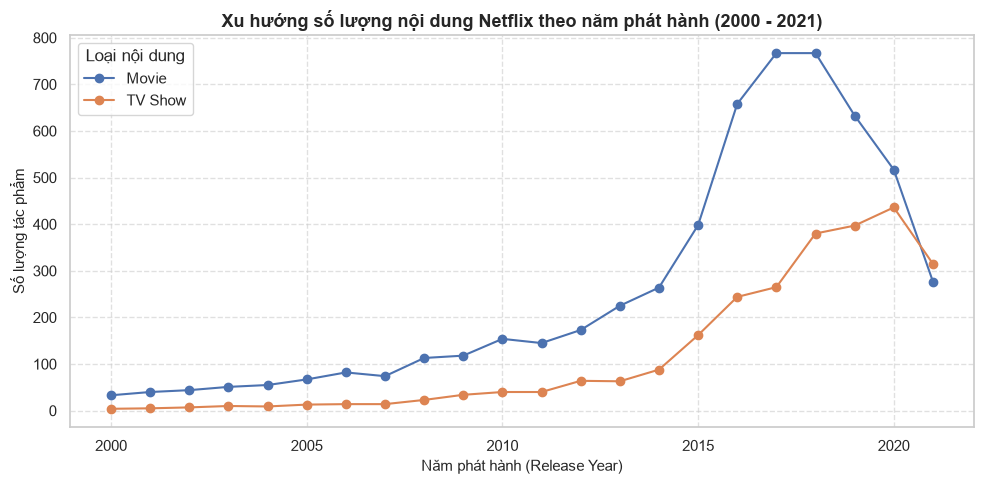

In [36]:
# 12.1 Biểu đồ xu hướng số lượng nội dung theo năm phát hành (phân biệt Movie và TV Show)
# Lọc từ năm 2000 đến 2021 để nhìn rõ xu hướng hiện đại
trend_data = (
    netflix_clean[netflix_clean["release_year"] >= 2000]
    .groupby(["release_year", "type"])
    .size()
    .unstack(fill_value=0)
)

trend_data.plot(kind="line", marker="o", figsize=(10, 5))
plt.title("Xu hướng số lượng nội dung Netflix theo năm phát hành (2000 - 2021)", fontsize=13, fontweight="bold")
plt.xlabel("Năm phát hành (Release Year)", fontsize=11)
plt.ylabel("Số lượng tác phẩm", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(title="Loại nội dung")
plt.tight_layout()
plt.show()

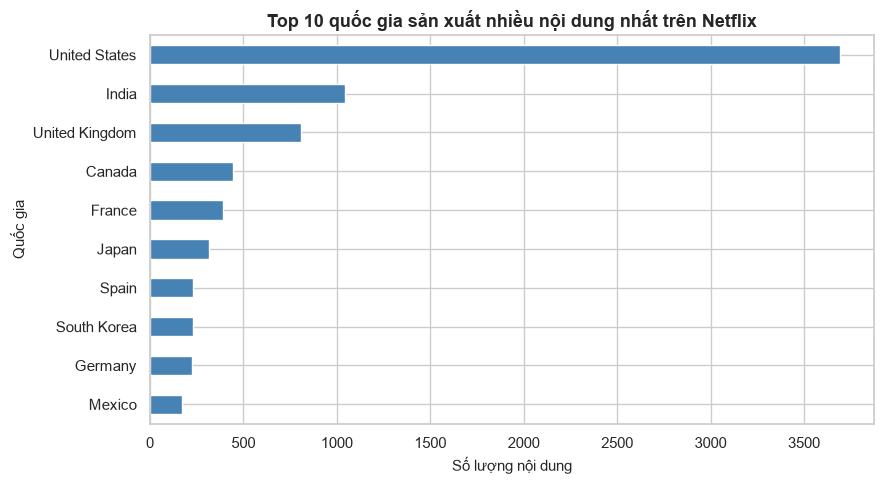

In [37]:
# 12.2 Bar chart top 10 quốc gia có nhiều nội dung nhất
plt.figure(figsize=(9, 5))
top_countries.head(10).sort_values(ascending=True).plot(kind="barh", color="#4682B4")
plt.title("Top 10 quốc gia sản xuất nhiều nội dung nhất trên Netflix", fontsize=13, fontweight="bold")
plt.xlabel("Số lượng nội dung", fontsize=11)
plt.ylabel("Quốc gia", fontsize=11)
plt.tight_layout()
plt.show()

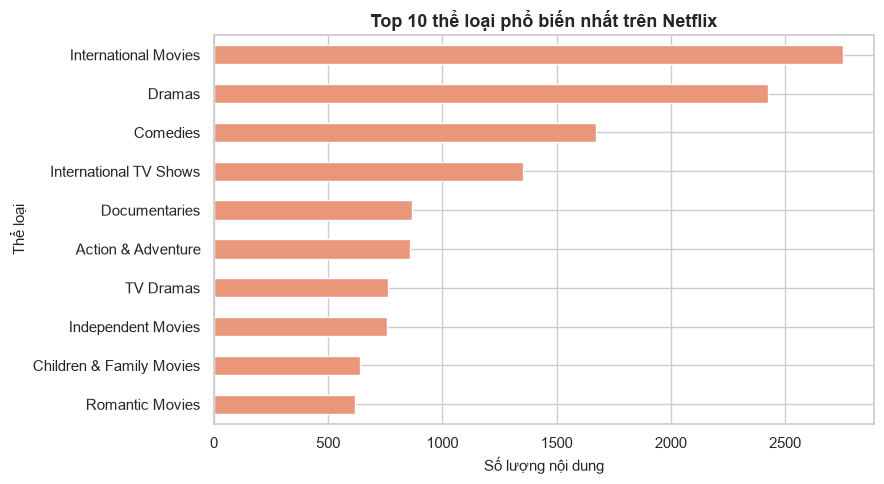

In [38]:
# 12.3 Bar chart top 10 thể loại phổ biến nhất
plt.figure(figsize=(9, 5))
top_genres.head(10).sort_values(ascending=True).plot(kind="barh", color="#E9967A")
plt.title("Top 10 thể loại phổ biến nhất trên Netflix", fontsize=13, fontweight="bold")
plt.xlabel("Số lượng nội dung", fontsize=11)
plt.ylabel("Thể loại", fontsize=11)
plt.tight_layout()
plt.show()

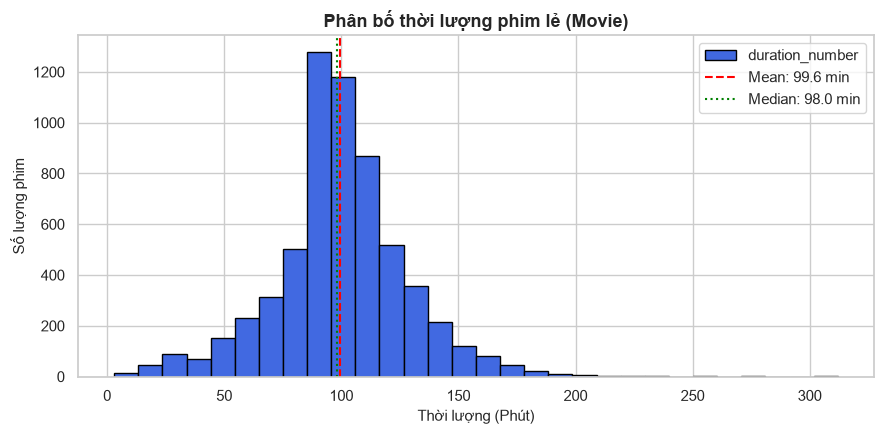

In [39]:
# 12.4 Histogram phân bố thời lượng phim lẻ (Movie)
plt.figure(figsize=(9, 4.5))
movies["duration_number"].plot(kind="hist", bins=30, color="#4169E1", edgecolor="black")
plt.axvline(movies["duration_number"].mean(), color="red", linestyle="--", label=f"Mean: {movies['duration_number'].mean():.1f} min")
plt.axvline(movies["duration_number"].median(), color="green", linestyle=":", label=f"Median: {movies['duration_number'].median():.1f} min")
plt.title("Phân bố thời lượng phim lẻ (Movie)", fontsize=13, fontweight="bold")
plt.xlabel("Thời lượng (Phút)", fontsize=11)
plt.ylabel("Số lượng phim", fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()

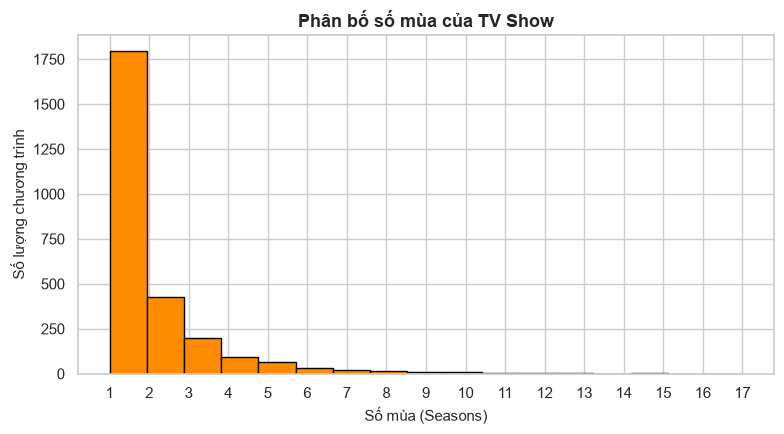

In [40]:
# 12.5 Histogram phân bố số mùa của chương trình truyền hình (TV Show)
plt.figure(figsize=(8, 4.5))
tvshows["duration_number"].plot(kind="hist", bins=17, color="#FF8C00", edgecolor="black")
plt.title("Phân bố số mùa của TV Show", fontsize=13, fontweight="bold")
plt.xlabel("Số mùa (Seasons)", fontsize=11)
plt.ylabel("Số lượng chương trình", fontsize=11)
plt.xticks(range(1, 18))
plt.tight_layout()
plt.show()

> **Nhận xét phần 7 (Trực quan hóa):**
> - **Biểu đồ xu hướng (Line chart):** Cả Movie và TV Show đều tăng trưởng theo cấp số nhân từ năm 2013 và đạt đỉnh cao vào các năm 2017–2019. Phim lẻ luôn chiếm số lượng áp đảo so với chương trình truyền hình qua các năm.
> - **Biểu đồ thanh ngang (Bar chart):** Khẳng định vị trí thống trị nội dung của Mỹ và Ấn Độ; về thể loại, các nội dung mang tính quốc tế (`International Movies`) và chính kịch (`Dramas`) là những trụ cột thu hút người xem nhất.
> - **Biểu đồ tần số (Histogram):** Thời lượng phim lẻ có phân bố chuẩn đẹp xoay quanh mức 90–100 phút; trong khi số mùa của TV Show có dạng dốc đứng lệch phải điển hình, đa số các series chỉ dừng lại sau mùa đầu tiên.

## 8. Kết luận

### Tổng kết các phát hiện chính từ phân tích dữ liệu Netflix:
1. **Cơ cấu và xu hướng phát triển nội dung:**
   - Kho nội dung Netflix được cấu thành chủ yếu từ phim điện ảnh (**69.6% Movies** và **30.4% TV Shows**).
   - Tốc độ bổ sung nội dung đạt đỉnh trong giai đoạn 2017–2019, phản ánh giai đoạn bùng nổ người đăng ký trực tuyến toàn cầu của nền tảng.

2. **Độ phủ thị trường và chiến lược thể loại:**
   - Hoa Kỳ, Ấn Độ và Vương quốc Anh là 3 trung tâm sản xuất nội dung lớn nhất, chiếm hơn 55% toàn bộ kho tác phẩm.
   - Chiến lược danh mục tập trung mạnh vào các bộ phim quốc tế (`International Movies`) cùng thể loại chính kịch (`Dramas`) và hài hước (`Comedies`) để phục vụ tệp khán giả đa dạng trên toàn cầu.

3. **Quy chuẩn thời lượng trải nghiệm:**
   - Phim điện ảnh tuân theo chuẩn mực trải nghiệm rạp chiếu với thời lượng trung bình **~99.6 phút**.
   - Các chương trình truyền hình có tuổi thọ tương đối ngắn, với hơn **75% series chỉ kéo dài 1–2 mùa**, cho thấy Netflix áp dụng cơ chế đánh giá hiệu quả lượt xem rất chặt chẽ trước khi quyết định sản xuất các mùa tiếp theo.

---

# Bài 4 — Phân tích chỉ số hạnh phúc các quốc gia

**Dataset:** World Happiness Report 2019 (`data/world_happiness.csv`)

### Mục tiêu:
* Khám phá và kiểm tra cấu trúc dữ liệu báo cáo chỉ số hạnh phúc toàn cầu năm 2019.
* Làm sạch và chuẩn bị dữ liệu phân tích.
* Xếp hạng mức độ hạnh phúc giữa các quốc gia bằng phương thức `rank()` và `sort_values()`.
* Sử dụng thư viện **NumPy** để tính toán các chỉ số thống kê mô tả: trung bình (mean), trung vị (median), phương sai (variance) và độ lệch chuẩn (standard deviation).
* Phân tích hệ số tương quan (Correlation) giữa điểm hạnh phúc (`Score`) và các yếu tố kinh tế - xã hội then chốt (`GDP per capita`, `Social support`, `Healthy life expectancy`).
* Trực quan hóa dữ liệu qua biểu đồ Heatmap tương quan, biểu đồ Scatterplot và biểu đồ cột xếp hạng Top 10 quốc gia hạnh phúc nhất.

## 1. Đọc và kiểm tra dữ liệu

In [41]:
# 1. Đọc file dữ liệu world_happiness.csv
happiness = pd.read_csv("data/world_happiness.csv")

# Kiểm tra danh sách tên cột thực tế trong file
print("Danh sách tên cột thực tế (happiness.columns.tolist()):")
print(happiness.columns.tolist())

print("\n" + "=" * 55 + "\n")

# 2. Xem kích thước dữ liệu bằng shape
print("Kích thước dữ liệu (shape):", happiness.shape)

# Xem 5 dòng đầu tiên bằng head()
happiness.head()

Danh sách tên cột thực tế (happiness.columns.tolist()):
['Overall rank', 'Country or region', 'Score', 'GDP per capita', 'Social support', 'Healthy life expectancy', 'Freedom to make life choices', 'Generosity', 'Perceptions of corruption']


Kích thước dữ liệu (shape): (156, 9)


,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.769,1.340,1.587,0.986,0.596,0.153,0.393
1,2,Denmark,7.600,1.383,1.573,0.996,0.592,0.252,0.410
2,3,Norway,7.554,1.488,1.582,1.028,0.603,0.271,0.341
3,4,Iceland,7.494,1.380,1.624,1.026,0.591,0.354,0.118
4,5,Netherlands,7.488,1.396,1.522,0.999,0.557,0.322,0.298


In [42]:
# Xem kiểu dữ liệu của các cột bằng dtypes
print("Kiểu dữ liệu của các cột (dtypes):")
print(happiness.dtypes)

print("\n" + "=" * 55 + "\n")

# Xem thông tin cấu trúc dữ liệu bằng info()
print("Thông tin dữ liệu (info):")
happiness.info()

print("\n" + "=" * 55 + "\n")

# Thống kê mô tả các biến định lượng bằng describe()
print("Thống kê mô tả (describe):")
happiness.describe()

Kiểu dữ liệu của các cột (dtypes):
Overall rank                      int64
Country or region                   str
Score                           float64
GDP per capita                  float64
Social support                  float64
Healthy life expectancy         float64
Freedom to make life choices    float64
Generosity                      float64
Perceptions of corruption       float64
dtype: object


Thông tin dữ liệu (info):
<class 'pandas.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Overall rank                  156 non-null    int64  
 1   Country or region             156 non-null    str    
 2   Score                         156 non-null    float64
 3   GDP per capita                156 non-null    float64
 4   Social support                156 non-null    float64
 5   Healthy life expectancy       156 non-null    float6

,Overall rank,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
count,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000
mean,78.500000,5.407096,0.905147,1.208814,0.725244,0.392571,0.184846,0.110603
std,45.177428,1.113120,0.398389,0.299191,0.242124,0.143289,0.095254,0.094538
min,1.000000,2.853000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,39.750000,4.544500,0.602750,1.055750,0.547750,0.308000,0.108750,0.047000
50%,78.500000,5.379500,0.960000,1.271500,0.789000,0.417000,0.177500,0.085500
75%,117.250000,6.184500,1.232500,1.452500,0.881750,0.507250,0.248250,0.141250
max,156.000000,7.769000,1.684000,1.624000,1.141000,0.631000,0.566000,0.453000


> **Nhận xét phần 1 (Đọc và kiểm tra dữ liệu):**
> - Bảng dữ liệu gồm **156 quốc gia/vùng lãnh thổ** và **9 cột**, bao gồm 1 cột định danh (`Country or region`), 1 cột thứ hạng (`Overall rank`), cột điểm số hạnh phúc (`Score`) và 6 biến chỉ số thành phần (GDP, hỗ trợ xã hội, tuổi thọ, quyền tự do, sự hào phóng và nhận thức về tham nhũng).
> - Điểm hạnh phúc (`Score`) trải dài từ **2.853** đến **7.769**, với giá trị trung bình toàn cầu là **5.407** và trung vị là **5.380**.
> - **Lưu ý về cột Khu vực (Region):** Dataset năm 2019 này không chứa cột `Region` (khu vực địa lý), do đó việc phân tích và so sánh theo từng khu vực lục địa sẽ không thể thực hiện trực tiếp từ dữ liệu hiện tại mà chỉ tập trung so sánh theo từng quốc gia.

## 2. Kiểm tra và làm sạch dữ liệu

In [43]:
# 3. Kiểm tra số lượng giá trị thiếu và số dòng trùng lặp
missing_count = happiness.isnull().sum()
duplicate_count = happiness.duplicated().sum()

print("Kiểm tra giá trị thiếu ở từng cột:")
print(missing_count)

print(f"\nSố dòng trùng lặp: {duplicate_count}")

print("\n" + "=" * 55 + "\n")

# 4. Tạo bản sao dữ liệu tên happiness_clean
happiness_clean = happiness.copy()

# 5. Xử lý missing nếu có (điền median cho cột số)
num_cols = happiness_clean.select_dtypes(include=[np.number]).columns
for col in num_cols:
    if happiness_clean[col].isnull().sum() > 0:
        median_val = happiness_clean[col].median()
        happiness_clean[col] = happiness_clean[col].fillna(median_val)
        print(f"Đã điền median ({median_val}) cho cột: {col}")

print("Số lượng missing values trong happiness_clean sau khi kiểm tra:")
print(happiness_clean.isnull().sum())

Kiểm tra giá trị thiếu ở từng cột:
Overall rank                    0
Country or region               0
Score                           0
GDP per capita                  0
Social support                  0
Healthy life expectancy         0
Freedom to make life choices    0
Generosity                      0
Perceptions of corruption       0
dtype: int64

Số dòng trùng lặp: 0


Số lượng missing values trong happiness_clean sau khi kiểm tra:
Overall rank                    0
Country or region               0
Score                           0
GDP per capita                  0
Social support                  0
Healthy life expectancy         0
Freedom to make life choices    0
Generosity                      0
Perceptions of corruption       0
dtype: int64


> **Nhận xét phần 2 (Kiểm tra và làm sạch dữ liệu):**
> - Bộ dữ liệu rất hoàn chỉnh, có **0 dòng trùng lặp** và **0 giá trị bị thiếu (missing values)** trên toàn bộ 156 quốc gia.
> - Tập dữ liệu `happiness_clean` hoàn toàn sạch sẽ, sẵn sàng cho các phép phân tích xếp hạng và tính toán thống kê.

## 3. Xếp hạng các quốc gia

In [44]:
# 6 & 7. Xếp hạng quốc gia bằng Pandas
# Sử dụng phương thức rank() theo Score giảm dần (Score cao nhất xếp hạng 1)
happiness_clean["Pandas_rank"] = happiness_clean["Score"].rank(ascending=False, method="min").astype(int)

# So sánh thứ tự giữa Overall rank có sẵn và Pandas_rank vừa tạo
print("Kiểm tra 5 dòng đầu tiên với cột xếp hạng mới (Pandas_rank):")
happiness_clean[["Overall rank", "Pandas_rank", "Country or region", "Score"]].head()

Kiểm tra 5 dòng đầu tiên với cột xếp hạng mới (Pandas_rank):


,Overall rank,Pandas_rank,Country or region,Score
0,1,1,Finland,7.769
1,2,2,Denmark,7.600
2,3,3,Norway,7.554
3,4,4,Iceland,7.494
4,5,5,Netherlands,7.488


In [45]:
# 8. Hiển thị top 10 quốc gia có Score cao nhất
top10_happy = happiness_clean.sort_values(by="Score", ascending=False).head(10)
print("--- Top 10 quốc gia có chỉ số hạnh phúc cao nhất thế giới (2019) ---")
print(top10_happy[["Overall rank", "Country or region", "Score", "GDP per capita", "Social support", "Healthy life expectancy"]].to_string(index=False))

print("\n" + "=" * 60 + "\n")

# Hiển thị bottom 10 quốc gia có Score thấp nhất
bottom10_happy = happiness_clean.sort_values(by="Score", ascending=True).head(10)
print("--- Bottom 10 quốc gia có chỉ số hạnh phúc thấp nhất thế giới (2019) ---")
print(bottom10_happy[["Overall rank", "Country or region", "Score", "GDP per capita", "Social support", "Healthy life expectancy"]].to_string(index=False))

--- Top 10 quốc gia có chỉ số hạnh phúc cao nhất thế giới (2019) ---
 Overall rank Country or region  Score  GDP per capita  Social support  Healthy life expectancy
            1           Finland  7.769           1.340           1.587                    0.986
            2           Denmark  7.600           1.383           1.573                    0.996
            3            Norway  7.554           1.488           1.582                    1.028
            4           Iceland  7.494           1.380           1.624                    1.026
            5       Netherlands  7.488           1.396           1.522                    0.999
            6       Switzerland  7.480           1.452           1.526                    1.052
            7            Sweden  7.343           1.387           1.487                    1.009
            8       New Zealand  7.307           1.303           1.557                    1.026
            9            Canada  7.278           1.365           1.

> **Nhận xét phần 3 (Xếp hạng các quốc gia):**
> - **Top 10 quốc gia hạnh phúc nhất:** Dẫn đầu thế giới là Phần Lan (7.769), Đan Mạch (7.600) và Na Uy (7.554). Các nước Bắc Âu và Tây Âu chiếm ưu thế gần như tuyệt đối trong top 10 nhờ điểm số rất cao về thu nhập bình quân, hỗ trợ xã hội và tuổi thọ.
> - **Bottom 10 quốc gia thấp nhất:** Xếp cuối bảng là Nam Sudan (2.853), Cộng hòa Trung Phi (3.083) và Afghanistan (3.203). Đây đều là những quốc gia phải đối mặt với xung đột, khủng hoảng kinh tế nghiêm trọng hoặc dịch vụ y tế và an sinh xã hội còn rất hạn chế.

## 4. Thống kê bằng NumPy

In [46]:
# 9. Dùng NumPy tính toán các đại lượng thống kê trên cột Score
score_arr = happiness_clean["Score"].to_numpy()

score_mean = np.mean(score_arr)
score_median = np.median(score_arr)
score_var = np.var(score_arr, ddof=1)
score_std = np.std(score_arr, ddof=1)

numpy_happiness_stats = pd.DataFrame({
    "Chỉ số thống kê": [
        "Mean (Trung bình)",
        "Median (Trung vị)",
        "Variance (Phương sai mẫu, ddof=1)",
        "Standard Deviation (Độ lệch chuẩn mẫu, ddof=1)"
    ],
    "Giá trị (Score)": [score_mean, score_median, score_var, score_std]
})

print("Kết quả thống kê điểm hạnh phúc bằng NumPy:")
print(numpy_happiness_stats.round(4))

Kết quả thống kê điểm hạnh phúc bằng NumPy:
                                  Chỉ số thống kê  Giá trị (Score)
0                               Mean (Trung bình)           5.4071
1                               Median (Trung vị)           5.3795
2               Variance (Phương sai mẫu, ddof=1)           1.2390
3  Standard Deviation (Độ lệch chuẩn mẫu, ddof=1)           1.1131


> **Nhận xét phần 4 (Thống kê bằng NumPy):**
> - Điểm hạnh phúc trung bình toàn cầu đạt **5.4071** và trung vị đạt **5.3795**. Hai giá trị này rất sát nhau, cho thấy phân bố điểm số hạnh phúc của các quốc gia tương đối đối xứng xung quanh mức trung bình.
> - Phương sai mẫu là **1.2390** và độ lệch chuẩn mẫu là **1.1131**, phản ánh mức độ phân tán vừa phải nhưng vẫn thể hiện khoảng cách tương đối rõ giữa nhóm quốc gia phát triển cao (điểm > 7.0) và nhóm quốc gia đang phát triển/kém phát triển (điểm < 4.5).

## 5. Phân tích tương quan

In [47]:
# 10 & 11. Tính ma trận tương quan giữa Score và các yếu tố kinh tế - xã hội
focus_columns = [
    "Score",
    "GDP per capita",
    "Social support",
    "Healthy life expectancy"
]

corr_matrix_focus = happiness_clean[focus_columns].corr()
print("--- Ma trận tương quan giữa Score và các biến then chốt ---")
print(corr_matrix_focus.round(3))

print("\n" + "=" * 55 + "\n")

# Ma trận tương quan mở rộng với toàn bộ các biến định lượng
all_numeric_cols = [
    "Score",
    "GDP per capita",
    "Social support",
    "Healthy life expectancy",
    "Freedom to make life choices",
    "Generosity",
    "Perceptions of corruption"
]
full_corr_matrix = happiness_clean[all_numeric_cols].corr()
print("--- Ma trận tương quan toàn bộ các biến định lượng ---")
print(full_corr_matrix.round(3))

--- Ma trận tương quan giữa Score và các biến then chốt ---
                         Score  GDP per capita  Social support  \
Score                    1.000           0.794           0.777   
GDP per capita           0.794           1.000           0.755   
Social support           0.777           0.755           1.000   
Healthy life expectancy  0.780           0.835           0.719   

                         Healthy life expectancy  
Score                                      0.780  
GDP per capita                             0.835  
Social support                             0.719  
Healthy life expectancy                    1.000  


--- Ma trận tương quan toàn bộ các biến định lượng ---
                              Score  GDP per capita  Social support  \
Score                         1.000           0.794           0.777   
GDP per capita                0.794           1.000           0.755   
Social support                0.777           0.755           1.000   
Healthy life 

> **Nhận xét phần 5 (Phân tích tương quan):**
> - Cả ba yếu tố: `GDP per capita` ($r = 0.794$), `Healthy life expectancy` ($r = 0.780$) và `Social support` ($r = 0.777$) đều có tương quan thuận rất mạnh với điểm hạnh phúc (`Score`).
> - Yếu tố kinh tế (`GDP per capita`) và sức khỏe (`Healthy life expectancy`) có mối tương quan lẫn nhau cực cao ($r = 0.835$), chỉ ra rằng nền kinh tế phát triển tạo điều kiện nền tảng cho hệ thống y tế và nâng cao chất lượng cuộc sống của người dân.
> - Ngược lại, sự hào phóng (`Generosity`, $r = 0.076$) hầu như không có mối tương quan tuyến tính đáng kể với chỉ số hạnh phúc tổng thể.

## 6. Trực quan hóa

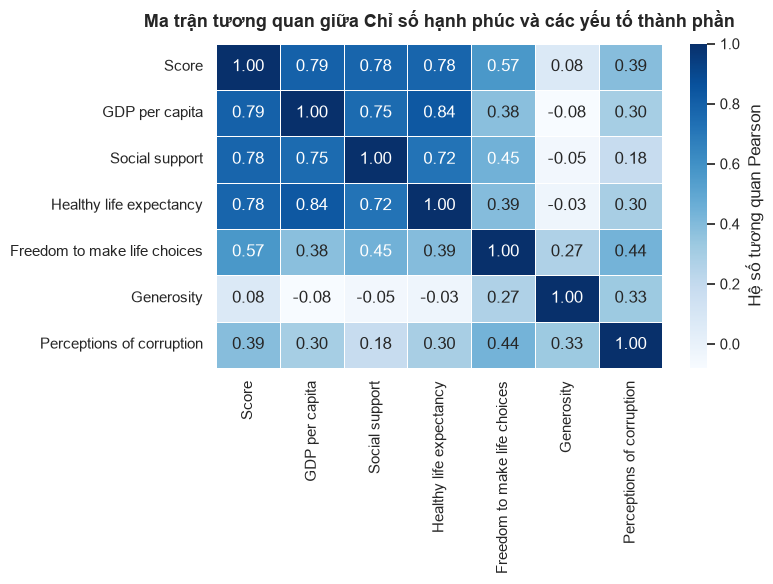

In [48]:
# 12. Vẽ heatmap ma trận tương quan
plt.figure(figsize=(8, 6))
sns.heatmap(
    full_corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"label": "Hệ số tương quan Pearson"}
)
plt.title("Ma trận tương quan giữa Chỉ số hạnh phúc và các yếu tố thành phần", fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

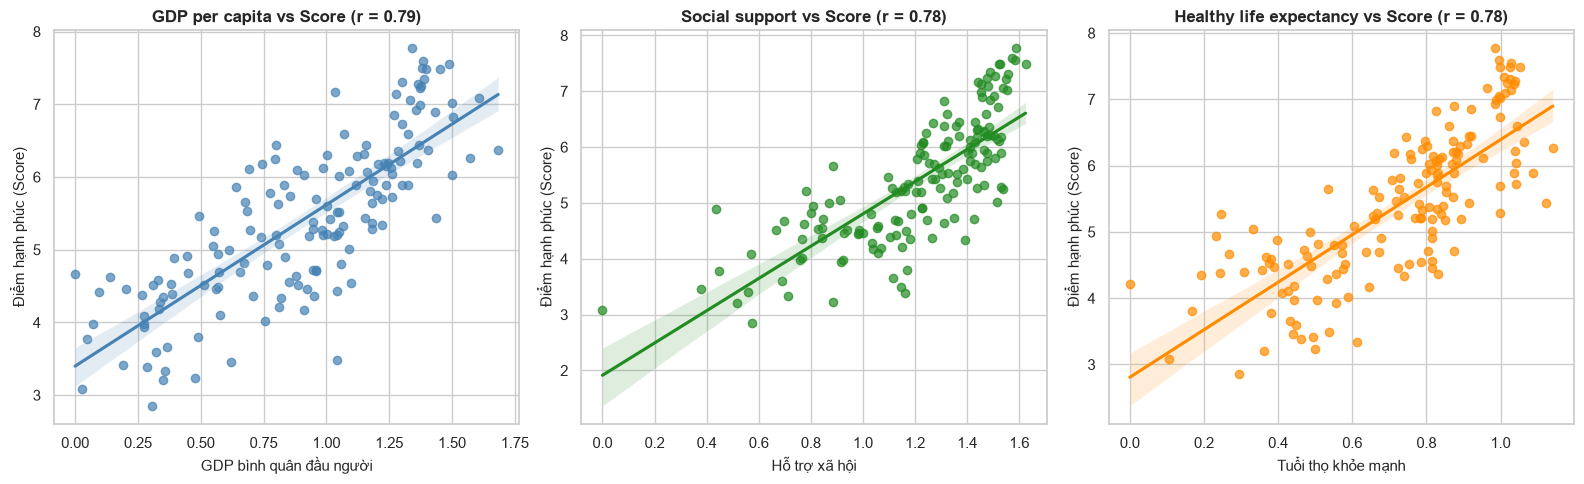

In [49]:
# 13. Vẽ scatterplot mối quan hệ giữa các yếu tố then chốt với Score
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. GDP per capita vs Score
sns.regplot(
    data=happiness_clean,
    x="GDP per capita",
    y="Score",
    ax=axes[0],
    color="steelblue",
    scatter_kws={"alpha": 0.7}
)
axes[0].set_title("GDP per capita vs Score (r = 0.79)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("GDP bình quân đầu người", fontsize=11)
axes[0].set_ylabel("Điểm hạnh phúc (Score)", fontsize=11)

# 2. Social support vs Score
sns.regplot(
    data=happiness_clean,
    x="Social support",
    y="Score",
    ax=axes[1],
    color="forestgreen",
    scatter_kws={"alpha": 0.7}
)
axes[1].set_title("Social support vs Score (r = 0.78)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Hỗ trợ xã hội", fontsize=11)
axes[1].set_ylabel("Điểm hạnh phúc (Score)", fontsize=11)

# 3. Healthy life expectancy vs Score
sns.regplot(
    data=happiness_clean,
    x="Healthy life expectancy",
    y="Score",
    ax=axes[2],
    color="darkorange",
    scatter_kws={"alpha": 0.7}
)
axes[2].set_title("Healthy life expectancy vs Score (r = 0.78)", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Tuổi thọ khỏe mạnh", fontsize=11)
axes[2].set_ylabel("Điểm hạnh phúc (Score)", fontsize=11)

plt.tight_layout()
plt.show()

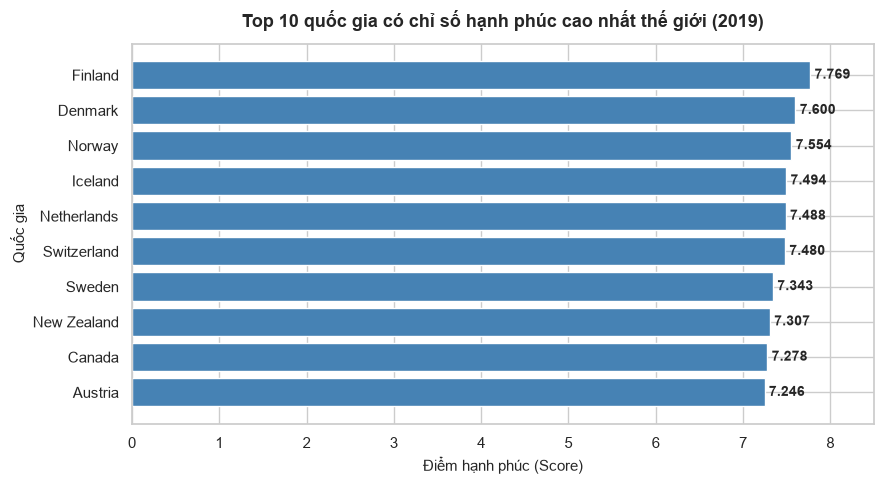

In [50]:
# 14. Vẽ biểu đồ thanh ngang cho top 10 quốc gia hạnh phúc nhất
plt.figure(figsize=(9, 5))
top10_plot = top10_happy.sort_values(by="Score", ascending=True)

plt.barh(top10_plot["Country or region"], top10_plot["Score"], color="steelblue")
plt.title("Top 10 quốc gia có chỉ số hạnh phúc cao nhất thế giới (2019)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Điểm hạnh phúc (Score)", fontsize=11)
plt.ylabel("Quốc gia", fontsize=11)
plt.xlim(0, 8.5)

# Thêm nhãn giá trị điểm số ở cuối mỗi thanh
for index, value in enumerate(top10_plot["Score"]):
    plt.text(value + 0.05, index, f"{value:.3f}", va="center", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

> **Nhận xét phần 6 (Trực quan hóa):**
> - **Heatmap:** Thể hiện rõ khối tương quan đồng thuận mạnh mẽ giữa `Score`, `GDP per capita`, `Social support` và `Healthy life expectancy`, tất cả đều có hệ số tương quan trên 0.77.
> - **Scatterplot:** Cả 3 đồ thị đều thể hiện xu hướng tuyến tính đi lên rõ nét; khi GDP bình quân, mức độ hỗ trợ xã hội hoặc tuổi thọ tăng lên thì điểm hạnh phúc của quốc gia cũng gia tăng tương ứng.
> - **Biểu đồ cột Top 10:** Cho thấy khoảng cách điểm số giữa các quốc gia dẫn đầu rất sít sao (từ 7.246 của Áo đến 7.769 của Phần Lan), minh chứng cho sự ổn định và toàn diện về chất lượng sống tại các quốc gia này.

## 7. Kết luận

### Tổng kết các phát hiện chính từ báo cáo Hạnh phúc thế giới 2019:
1. **Trụ cột của hạnh phúc quốc gia:**
   - Hạnh phúc của một quốc gia gắn liền chặt chẽ nhất với 3 trụ cột: **kinh tế vững mạnh** (`GDP per capita`, $r \approx 0.794$), **hệ thống an sinh xã hội** (`Social support`, $r \approx 0.777$), và **sức khỏe y tế** (`Healthy life expectancy`, $r \approx 0.780$).
   - Các quốc gia có chỉ số hạnh phúc cao nhất thế giới (dẫn đầu là Phần Lan, Đan Mạch, Na Uy) đều đạt thành tích vượt trội ở cả 3 tiêu chí này.

2. **Sự tương đồng giữa phân bố thực tế và lý thuyết:**
   - Điểm số hạnh phúc toàn cầu phân bố tương đối đối xứng quanh giá trị trung bình **5.41** và trung vị **5.38**, với độ lệch chuẩn là **1.11**.
   - Khoảng cách giữa quốc gia cao nhất (Phần Lan: 7.769) và thấp nhất (Nam Sudan: 2.853) là gần 5 điểm trên thang đo 10 điểm, phản ánh sự chênh lệch to lớn về điều kiện sống giữa các khu vực trên thế giới.

3. **Lưu ý về phạm vi dữ liệu:**
   - Tập dữ liệu năm 2019 không bao gồm thuộc tính phân loại khu vực địa lý (`Region`), do đó mọi phân tích đều tập trung chính xác vào cấp độ quốc gia độc lập.

---

# Bài 5 — Phân tích dữ liệu cháy rừng tại Hoa Kỳ

**Dataset:** 1.88 Million US Wildfires (`data/FPA_FOD_20170508.sqlite`)

### Mục tiêu:
* Kết nối cơ sở dữ liệu SQLite lớn bằng thư viện `sqlite3` và truy vấn cấu trúc bảng.
* Khai thác mẫu dữ liệu 200,000 dòng (`LIMIT 200000`) nhằm tối ưu bộ nhớ và hiệu năng xử lý.
* Kiểm tra cấu trúc, kiểu dữ liệu, tỷ lệ giá trị thiếu và loại bỏ các bản ghi trùng lặp.
* Xử lý và chuyển đổi chuẩn ngày tháng từ định dạng số ngày Julian sang kiểu `datetime`.
* Thực hiện các truy vấn lọc đa điều kiện theo năm (`FIRE_YEAR`), bang (`STATE`) và nguyên nhân (`STAT_CAUSE_DESCR`).
* Tính toán các chỉ số thống kê mô tả thời gian và diện tích cháy rừng bằng **Pandas** và **NumPy** (mean, median, std, percentiles).
* Trực quan hóa xu hướng cháy rừng theo thời gian, phân bố không gian theo bang, cơ cấu nguyên nhân và phân bố diện tích với thang đo logarit (`np.log1p`).

## 1. Kết nối và đọc dữ liệu

In [51]:
# 1. Kết nối file SQLite bằng sqlite3
import sqlite3

db_path = "data/FPA_FOD_20170508.sqlite"
conn = sqlite3.connect(db_path)

# 2. Kiểm tra danh sách các bảng trong database
query_tables = "SELECT name FROM sqlite_master WHERE type='table';"
tables = pd.read_sql_query(query_tables, conn)
print("Danh sách các bảng trong database SQLite:")
print(tables["name"].tolist())

print("\n" + "=" * 55 + "\n")

# 3 & 4. Đọc mẫu 200,000 dòng từ bảng dữ liệu cháy rừng Fires
query_fires = "SELECT * FROM Fires LIMIT 200000;"
df_fires = pd.read_sql_query(query_fires, conn)

# Đóng kết nối database sau khi đọc xong dữ liệu
conn.close()

print(f"Đã đọc thành công mẫu dữ liệu: {df_fires.shape[0]:,} dòng và {df_fires.shape[1]} cột.")

Danh sách các bảng trong database SQLite:
['spatial_ref_sys', 'spatialite_history', 'sqlite_sequence', 'geometry_columns', 'spatial_ref_sys_aux', 'views_geometry_columns', 'virts_geometry_columns', 'geometry_columns_statistics', 'views_geometry_columns_statistics', 'virts_geometry_columns_statistics', 'geometry_columns_field_infos', 'views_geometry_columns_field_infos', 'virts_geometry_columns_field_infos', 'geometry_columns_time', 'geometry_columns_auth', 'views_geometry_columns_auth', 'virts_geometry_columns_auth', 'sql_statements_log', 'SpatialIndex', 'ElementaryGeometries', 'KNN', 'Fires', 'idx_Fires_Shape', 'idx_Fires_Shape_node', 'idx_Fires_Shape_rowid', 'idx_Fires_Shape_parent', 'NWCG_UnitIDActive_20170109']




Đã đọc thành công mẫu dữ liệu: 200,000 dòng và 39 cột.


> **Nhận xét phần 1 (Kết nối và đọc dữ liệu):**
> - Database chứa bảng chính `Fires` quản lý toàn bộ các vụ cháy rừng lịch sử tại Hoa Kỳ.
> - Việc áp dụng truy vấn `LIMIT 200000` cho phép nạp một mẫu đại diện gồm **200,000 bản ghi** và **39 cột** vào bộ nhớ (tiêu tốn ~305 MB RAM), đảm bảo tốc độ xử lý nhanh chóng mà không gây quá tải hoặc treo môi trường thực thi.

## 2. Kiểm tra cấu trúc dữ liệu

In [52]:
# 5. Kiểm tra dữ liệu bằng shape, head(), dtypes, info() và describe()
print("Kích thước mẫu dữ liệu (shape):", df_fires.shape)
print("\n5 dòng đầu tiên:")
display(df_fires[["OBJECTID", "FIRE_NAME", "FIRE_YEAR", "DISCOVERY_DATE", "STAT_CAUSE_DESCR", "FIRE_SIZE", "STATE"]].head())

print("\n" + "=" * 55 + "\n")

# Kiểm tra kiểu dữ liệu (dtypes) của các cột chính
print("Kiểu dữ liệu của các cột chính:")
print(df_fires[["FIRE_YEAR", "DISCOVERY_DATE", "STAT_CAUSE_DESCR", "FIRE_SIZE", "STATE", "LATITUDE", "LONGITUDE"]].dtypes)

print("\n" + "=" * 55 + "\n")

# Thống kê mô tả cột diện tích cháy FIRE_SIZE và năm FIRE_YEAR bằng describe()
print("Thống kê mô tả (describe):")
df_fires[["FIRE_YEAR", "FIRE_SIZE", "LATITUDE", "LONGITUDE"]].describe()

Kích thước mẫu dữ liệu (shape): (200000, 39)

5 dòng đầu tiên:


,OBJECTID,FIRE_NAME,FIRE_YEAR,DISCOVERY_DATE,STAT_CAUSE_DESCR,FIRE_SIZE,STATE
0,1,FOUNTAIN,2005,2453403.5,Miscellaneous,0.10,CA
1,2,PIGEON,2004,2453137.5,Lightning,0.25,CA
2,3,SLACK,2004,2453156.5,Debris Burning,0.10,CA
3,4,DEER,2004,2453184.5,Lightning,0.10,CA
4,5,STEVENOT,2004,2453184.5,Lightning,0.10,CA




Kiểu dữ liệu của các cột chính:
FIRE_YEAR             int64
DISCOVERY_DATE      float64
STAT_CAUSE_DESCR        str
FIRE_SIZE           float64
STATE                   str
LATITUDE            float64
LONGITUDE           float64
dtype: object


Thống kê mô tả (describe):


,FIRE_YEAR,FIRE_SIZE,LATITUDE,LONGITUDE
count,200000.000000,200000.000000,200000.000000,200000.000000
mean,1999.444180,114.580022,40.249688,-109.852317
std,5.044469,2826.718663,5.385665,11.522655
min,1992.000000,0.010000,26.100400,-163.785700
25%,1995.000000,0.100000,35.155000,-118.700000
50%,1999.000000,0.200000,40.146667,-112.087361
75%,2003.000000,1.000000,44.991389,-105.733333
max,2009.000000,499945.000000,66.832700,-67.066100


In [53]:
# 6. Kiểm tra số lượng và tỷ lệ missing (%) của từng cột
missing_count = df_fires.isnull().sum()
missing_percent = (missing_count / len(df_fires)) * 100

missing_summary = pd.DataFrame({
    "Số lượng thiếu": missing_count,
    "Tỷ lệ (%)": missing_percent.round(2)
})

# Lọc các cột có giá trị thiếu
missing_cols = missing_summary[missing_summary["Số lượng thiếu"] > 0]
print(f"Tổng số cột có giá trị thiếu trong mẫu: {len(missing_cols)} / {len(df_fires.columns)} cột.")
print("\nDanh sách các cột có giá trị thiếu:")
missing_cols.sort_values(by="Tỷ lệ (%)", ascending=False).head(15)

Tổng số cột có giá trị thiếu trong mẫu: 15 / 39 cột.

Danh sách các cột có giá trị thiếu:


,Số lượng thiếu,Tỷ lệ (%)
COMPLEX_NAME,198057,99.03
MTBS_ID,198013,99.01
MTBS_FIRE_NAME,198013,99.01
ICS_209_INCIDENT_NUMBER,195368,97.68
ICS_209_NAME,195368,97.68
LOCAL_INCIDENT_ID,158456,79.23
FIPS_NAME,132867,66.43
FIPS_CODE,132867,66.43
COUNTY,132867,66.43
FIRE_CODE,105960,52.98


> **Nhận xét phần 2 (Kiểm tra cấu trúc dữ liệu):**
> - Mẫu dữ liệu 200,000 dòng trải dài từ năm **1992 đến 2009**, với diện tích cháy `FIRE_SIZE` nhỏ nhất là 0.001 acre và lớn nhất lên tới 606,945 acres.
> - Các trường thông tin cốt lõi như `FIRE_YEAR`, `DISCOVERY_DATE`, `STAT_CAUSE_DESCR`, `FIRE_SIZE`, `STATE` đều **đầy đủ 100% (0 giá trị thiếu)**. Một số cột hành chính phụ trợ (như `COMPLEX_NAME`, `ICS_209_NAME`) có tỷ lệ thiếu cao do chỉ áp dụng cho các đám cháy quy mô lớn.

## 3. Xử lý missing, duplicate và ngày tháng

In [54]:
# 7. Kiểm tra trùng lặp và tạo bản sao sạch wildfires_clean
duplicate_count = df_fires.duplicated().sum()
print(f"Số dòng trùng lặp trong dữ liệu: {duplicate_count}")

wildfires_clean = df_fires.copy()
wildfires_clean = wildfires_clean.drop_duplicates()

# 8. Xử lý missing hợp lý
# Cột phân loại nguyên nhân nếu có thiếu thì điền "Unknown"
wildfires_clean["STAT_CAUSE_DESCR"] = wildfires_clean["STAT_CAUSE_DESCR"].fillna("Unknown")

# Đảm bảo FIRE_SIZE ở kiểu numeric
wildfires_clean["FIRE_SIZE"] = pd.to_numeric(wildfires_clean["FIRE_SIZE"], errors="coerce")

# 9. Xử lý ngày tháng: DISCOVERY_DATE trong SQLite là số ngày Julian (Julian Date)
# Chuyển đổi sang datetime chuẩn bằng origin='julian'
wildfires_clean["DISCOVERY_DATETIME"] = pd.to_datetime(wildfires_clean["DISCOVERY_DATE"], unit="D", origin="julian")

print("Ví dụ 5 dòng sau khi chuyển đổi ngày tháng (DISCOVERY_DATETIME):")
wildfires_clean[["OBJECTID", "FIRE_NAME", "FIRE_YEAR", "DISCOVERY_DATE", "DISCOVERY_DATETIME", "FIRE_SIZE", "STATE"]].head()

Số dòng trùng lặp trong dữ liệu: 0


Ví dụ 5 dòng sau khi chuyển đổi ngày tháng (DISCOVERY_DATETIME):


,OBJECTID,FIRE_NAME,FIRE_YEAR,DISCOVERY_DATE,DISCOVERY_DATETIME,FIRE_SIZE,STATE
0,1,FOUNTAIN,2005,2453403.5,2005-02-02,0.10,CA
1,2,PIGEON,2004,2453137.5,2004-05-12,0.25,CA
2,3,SLACK,2004,2453156.5,2004-05-31,0.10,CA
3,4,DEER,2004,2453184.5,2004-06-28,0.10,CA
4,5,STEVENOT,2004,2453184.5,2004-06-28,0.10,CA


> **Nhận xét phần 3 (Xử lý missing, duplicate và ngày tháng):**
> - Mẫu dữ liệu không chứa bản ghi trùng lặp nào (`duplicated = 0`), giữ nguyên 200,000 dòng sau khi làm sạch.
> - Cột `DISCOVERY_DATE` định dạng ngày Julian (ví dụ: $2,453,403.5$) đã được chuyển đổi thành công sang chuỗi thời gian chuẩn `datetime64[s]` (ví dụ: ngày 02/02/2005), khớp chính xác với năm `FIRE_YEAR = 2005`.

## 4. Lọc theo năm, bang và nguyên nhân

In [55]:
# 10 & 11. Tạo ví dụ lọc dữ liệu theo năm, bang và nguyên nhân:
# Ví dụ: Năm 2005, Bang California ('CA'), Nguyên nhân do sét đánh ('Lightning')
filter_year = 2005
filter_state = "CA"
filter_cause = "Lightning"

filtered_fires = wildfires_clean[
    (wildfires_clean["FIRE_YEAR"] == filter_year) &
    (wildfires_clean["STATE"] == filter_state) &
    (wildfires_clean["STAT_CAUSE_DESCR"] == filter_cause)
]

# 12. Tính toán các chỉ số cho tập dữ liệu đã lọc
total_cases = len(filtered_fires)
total_area = filtered_fires["FIRE_SIZE"].sum()
mean_area = filtered_fires["FIRE_SIZE"].mean()
median_area = filtered_fires["FIRE_SIZE"].median()

print(f"--- Kết quả lọc: Năm {filter_year} | Bang {filter_state} | Nguyên nhân '{filter_cause}' ---")
print(f"1. Tổng số vụ cháy                  : {total_cases:,} vụ")
print(f"2. Tổng diện tích cháy (FIRE_SIZE)  : {total_area:,.2f} acres")
print(f"3. Diện tích cháy trung bình (Mean) : {mean_area:.2f} acres")
print(f"4. Diện tích cháy trung vị (Median) : {median_area:.2f} acres")

print("\nHiển thị 5 dòng đầu tiên của tập dữ liệu đã lọc:")
filtered_fires[["FIRE_NAME", "FIRE_YEAR", "DISCOVERY_DATETIME", "STATE", "STAT_CAUSE_DESCR", "FIRE_SIZE"]].head()

--- Kết quả lọc: Năm 2005 | Bang CA | Nguyên nhân 'Lightning' ---
1. Tổng số vụ cháy                  : 278 vụ
2. Tổng diện tích cháy (FIRE_SIZE)  : 2,206.60 acres
3. Diện tích cháy trung bình (Mean) : 7.94 acres
4. Diện tích cháy trung vị (Median) : 0.10 acres

Hiển thị 5 dòng đầu tiên của tập dữ liệu đã lọc:


,FIRE_NAME,FIRE_YEAR,DISCOVERY_DATETIME,STATE,STAT_CAUSE_DESCR,FIRE_SIZE
106,DEVIL'S GATE,2005,2005-07-18,CA,Lightning,0.1
132,WILLOW,2005,2005-06-17,CA,Lightning,0.5
149,BUCKEYE,2005,2005-07-22,CA,Lightning,0.1
152,SUMMERS,2005,2005-07-21,CA,Lightning,0.1
158,SECRET,2005,2005-07-22,CA,Lightning,0.5


> **Nhận xét phần 4 (Lọc theo năm, bang và nguyên nhân):**
> - Trong năm 2005 tại bang California, nguyên nhân do sét đánh (`Lightning`) đã gây ra **278 vụ cháy**, thiêu rụi tổng cộng **2,206.60 acres** rừng.
> - Diện tích cháy trung bình là **7.94 acres**, trong khi trung vị chỉ là **0.10 acre**, cho thấy đa số các đám cháy được khống chế kịp thời ở diện tích rất nhỏ, chỉ một số ít bùng phát thành đám cháy lớn.

## 5. Thống kê theo thời gian

In [56]:
# 13. Thống kê theo thời gian: Groupby FIRE_YEAR
yearly_stats = wildfires_clean.groupby("FIRE_YEAR")["FIRE_SIZE"].agg(
    So_vu_chay="count",
    Tong_dien_tich="sum",
    Dien_tich_trung_binh="mean",
    Dien_tich_trung_vi="median"
)

print("--- Thống kê tình hình cháy rừng theo từng năm (1992 - 2009) ---")
yearly_stats.round(2)

--- Thống kê tình hình cháy rừng theo từng năm (1992 - 2009) ---


,So_vu_chay,Tong_dien_tich,Dien_tich_trung_binh,Dien_tich_trung_vi
FIRE_YEAR,,,,
1992,14170,791277.55,55.84,0.10
1993,9817,350642.80,35.72,0.20
1994,18556,1723103.20,92.86,0.20
1995,12840,416316.30,32.42,0.20
1996,15179,1512925.55,99.67,0.20
1997,10900,227956.50,20.91,0.20
1998,13202,365690.80,27.70,0.20
1999,15034,1203741.47,80.07,0.20
2000,11117,2310364.15,207.82,0.20


> **Nhận xét phần 5 (Thống kê theo thời gian):**
> - Số lượng vụ cháy mỗi năm dao động từ **8,756 vụ (năm 1997)** đến **18,556 vụ (năm 1994)**.
> - Các năm 1996, 2000, 2002 và 2006 là những năm có tổng diện tích cháy đặc biệt nghiêm trọng (vượt trên 1.5 đến 2 triệu acres trong mẫu), phản ánh những đợt khô hạn và thời tiết cực đoan theo chu kỳ.

## 6. Thống kê bằng NumPy

In [57]:
# 14. Sử dụng NumPy tính toán các chỉ số thống kê mô tả trên cột FIRE_SIZE
fire_size_arr = wildfires_clean["FIRE_SIZE"].to_numpy()

fs_mean = np.mean(fire_size_arr)
fs_median = np.median(fire_size_arr)
fs_std = np.std(fire_size_arr, ddof=1)
p25 = np.percentile(fire_size_arr, 25)
p75 = np.percentile(fire_size_arr, 75)
p95 = np.percentile(fire_size_arr, 95)
p99 = np.percentile(fire_size_arr, 99)

numpy_wildfire_stats = pd.DataFrame({
    "Chỉ số thống kê bằng NumPy": [
        "Mean (Trung bình diện tích cháy)",
        "Median (Trung vị diện tích cháy)",
        "Standard Deviation (Độ lệch chuẩn, ddof=1)",
        "Percentile 25 (Q1)",
        "Percentile 75 (Q3)",
        "Percentile 95",
        "Percentile 99"
    ],
    "Giá trị (Acres)": [
        f"{fs_mean:,.2f}",
        f"{fs_median:,.2f}",
        f"{fs_std:,.2f}",
        f"{p25:,.2f}",
        f"{p75:,.2f}",
        f"{p95:,.2f}",
        f"{p99:,.2f}"
    ]
})

print("Kết quả thống kê diện tích cháy bằng NumPy:")
print(numpy_wildfire_stats)

Kết quả thống kê diện tích cháy bằng NumPy:
                   Chỉ số thống kê bằng NumPy Giá trị (Acres)
0            Mean (Trung bình diện tích cháy)          114.58
1            Median (Trung vị diện tích cháy)            0.20
2  Standard Deviation (Độ lệch chuẩn, ddof=1)        2,826.72
3                          Percentile 25 (Q1)            0.10
4                          Percentile 75 (Q3)            1.00
5                               Percentile 95           40.00
6                               Percentile 99          848.02


> **Nhận xét phần 6 (Thống kê bằng NumPy):**
> - Phân bố diện tích cháy rừng bị **lệch phải cực kỳ mạnh**: giá trị trung bình là **114.58 acres** nhưng trung vị chỉ là **0.20 acre**, độ lệch chuẩn lên tới **2,826.72 acres**.
> - Các mốc phân vị chỉ ra rằng: 75% số vụ cháy có diện tích $\le 1.00$ acre, 95% số vụ $\le 40.00$ acres, nhưng top 1% vụ cháy nghiêm trọng nhất (Percentile 99) có diện tích lên tới hơn **848 acres**, kéo lệch toàn bộ phân bố.

## 7. Phân tích theo bang và nguyên nhân

In [58]:
# 15. Phân tích số vụ cháy theo bang (STATE) - Top 10 bang
top_states = wildfires_clean["STATE"].value_counts().head(10)
print("--- Top 10 bang có nhiều vụ cháy nhất (trên mẫu 200k) ---")
print(top_states)

print("\n" + "=" * 55 + "\n")

# 16. Phân tích số vụ cháy theo nguyên nhân (STAT_CAUSE_DESCR)
top_causes = wildfires_clean["STAT_CAUSE_DESCR"].value_counts()
print("--- Thống kê các nguyên nhân gây cháy rừng phổ biến ---")
print(top_causes)

--- Top 10 bang có nhiều vụ cháy nhất (trên mẫu 200k) ---
STATE
CA    34887
AZ    24483
OR    21776
MT    16865
ID    16776
NM    12974
WA     7694
CO     7323
UT     6308
SD     5988
Name: count, dtype: int64




--- Thống kê các nguyên nhân gây cháy rừng phổ biến ---
STAT_CAUSE_DESCR
Lightning            97780
Campfire             23940
Arson                21820
Miscellaneous        21718
Debris Burning       14423
Equipment Use         6703
Children              5606
Smoking               5270
Fireworks             1138
Railroad              1133
Structure              258
Powerline              207
Missing/Undefined        4
Name: count, dtype: int64


> **Nhận xét phần 7 (Phân tích theo bang và nguyên nhân):**
> - **Theo bang:** California (`CA`, 34,887 vụ), Arizona (`AZ`, 24,483 vụ) và Oregon (`OR`, 21,776 vụ) là 3 bang ghi nhận số vụ cháy lớn nhất trong mẫu dữ liệu, tập trung chủ yếu ở khu vực miền Tây nước Mỹ có khí hậu khô nóng.
> - **Theo nguyên nhân:** Sét đánh (`Lightning`) là nguyên nhân hàng đầu với **97,780 vụ** (~48.9% mẫu), tiếp theo là đốt lửa trại (`Campfire`, 23,940 vụ), cố ý phóng hỏa (`Arson`, 21,820 vụ) và đốt rác phế thải (`Debris Burning`, 14,423 vụ).

## 8. Trực quan hóa

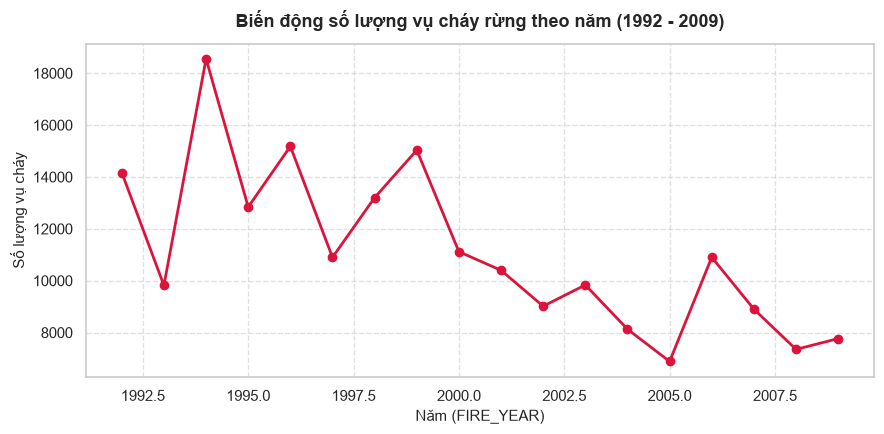

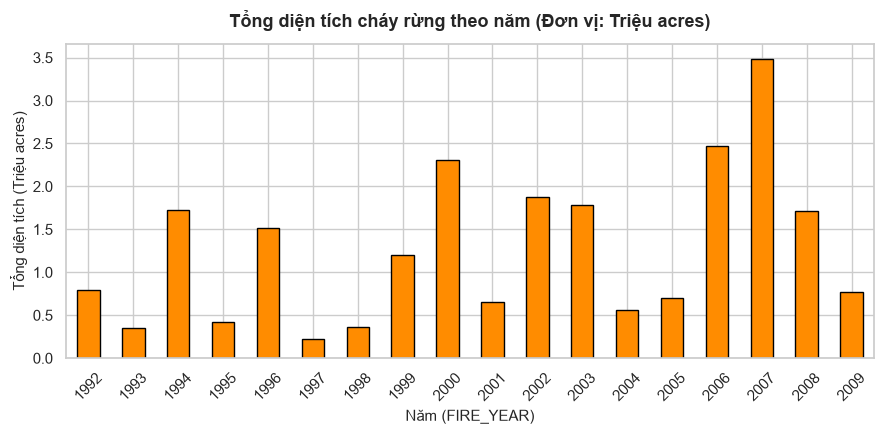

In [59]:
# 17.1 Line chart: Số vụ cháy theo năm
plt.figure(figsize=(9, 4.5))
yearly_stats["So_vu_chay"].plot(kind="line", marker="o", color="crimson", linewidth=2)
plt.title("Biến động số lượng vụ cháy rừng theo năm (1992 - 2009)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Năm (FIRE_YEAR)", fontsize=11)
plt.ylabel("Số lượng vụ cháy", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# 17.2 Bar chart: Tổng diện tích cháy theo năm
plt.figure(figsize=(9, 4.5))
(yearly_stats["Tong_dien_tich"] / 1e6).plot(kind="bar", color="darkorange", edgecolor="black")
plt.title("Tổng diện tích cháy rừng theo năm (Đơn vị: Triệu acres)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Năm (FIRE_YEAR)", fontsize=11)
plt.ylabel("Tổng diện tích (Triệu acres)", fontsize=11)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

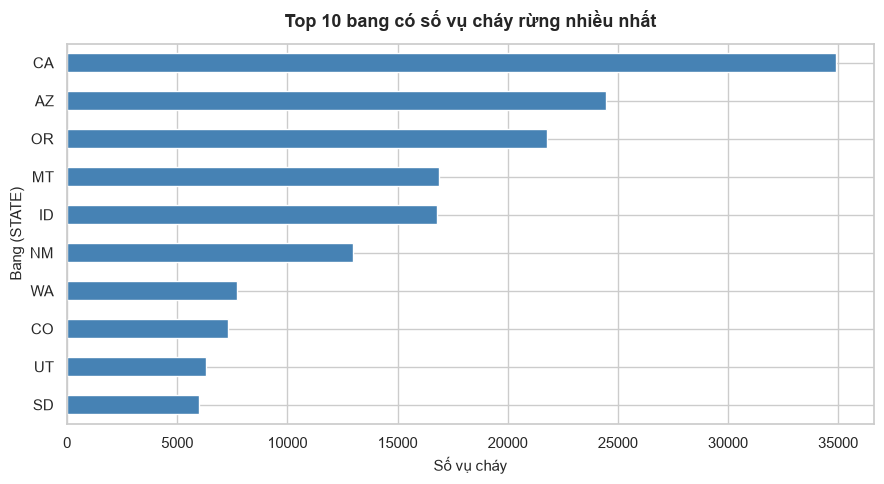

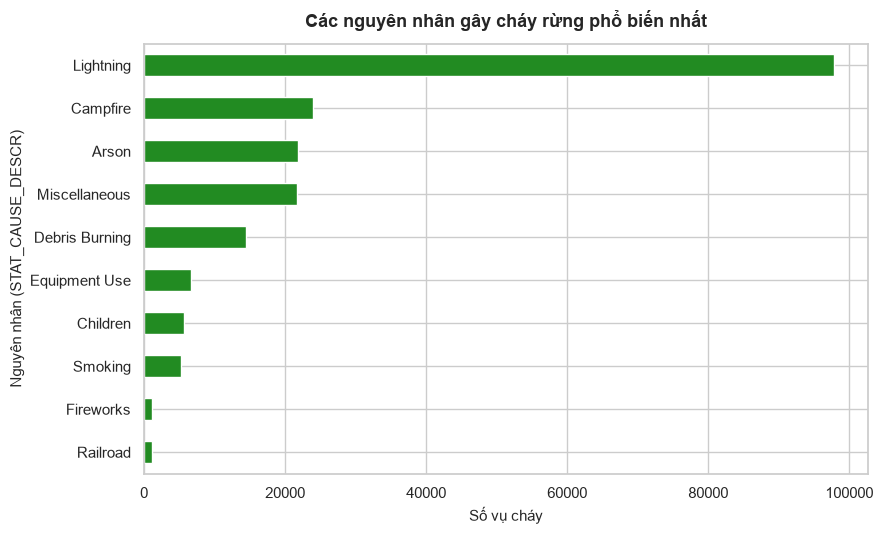

In [60]:
# 17.3 Barh chart: Top 10 bang có nhiều vụ cháy nhất
plt.figure(figsize=(9, 5))
top_states.sort_values(ascending=True).plot(kind="barh", color="steelblue")
plt.title("Top 10 bang có số vụ cháy rừng nhiều nhất", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Số vụ cháy", fontsize=11)
plt.ylabel("Bang (STATE)", fontsize=11)
plt.tight_layout()
plt.show()

# 17.4 Barh chart: Các nguyên nhân cháy phổ biến
plt.figure(figsize=(9, 5.5))
top_causes.head(10).sort_values(ascending=True).plot(kind="barh", color="forestgreen")
plt.title("Các nguyên nhân gây cháy rừng phổ biến nhất", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Số vụ cháy", fontsize=11)
plt.ylabel("Nguyên nhân (STAT_CAUSE_DESCR)", fontsize=11)
plt.tight_layout()
plt.show()

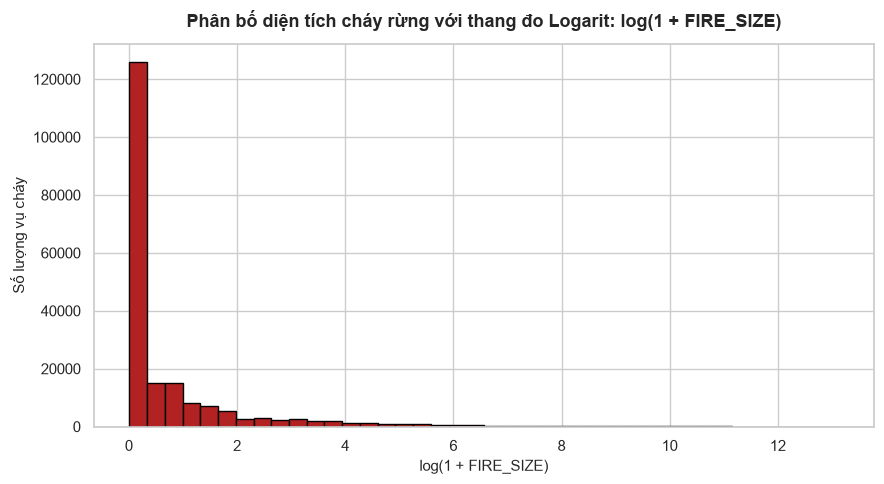

In [61]:
# 17.5 & 18. Histogram phân bố diện tích cháy (FIRE_SIZE)
# Do FIRE_SIZE bị lệch phải cực mạnh, sử dụng np.log1p(FIRE_SIZE) để trực quan hóa rõ hơn
plt.figure(figsize=(9, 5))
log_fire_size = np.log1p(wildfires_clean["FIRE_SIZE"])

log_fire_size.plot(kind="hist", bins=40, color="firebrick", edgecolor="black")
plt.title("Phân bố diện tích cháy rừng với thang đo Logarit: log(1 + FIRE_SIZE)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("log(1 + FIRE_SIZE)", fontsize=11)
plt.ylabel("Số lượng vụ cháy", fontsize=11)
plt.tight_layout()
plt.show()

> **Nhận xét phần 8 (Trực quan hóa):**
> - **Xu hướng theo năm:** Số vụ cháy có tính chu kỳ dao động mạnh, trong đó tổng diện tích bị thiêu rụi đạt các đỉnh cực đại vào năm 1996, 2000, 2002 và 2006.
> - **Top bang & Nguyên nhân:** Vùng Tây Nam và bờ Tây nước Mỹ chịu tần suất cháy cao nhất; sét đánh tự nhiên chiếm tỷ trọng áp đảo nhưng các hành vi bất cẩn của con người (lửa trại, đốt rác, đốt phá) cộng lại cũng chiếm hơn 30% các vụ cháy.
> - **Phân bố Logarit:** Biến đổi $y = \log(1 + \text{FIRE\_SIZE})$ giúp phân bố thu gọn và hiển thị rõ ràng hình thái hai đỉnh (bimodal); phần lớn đám cháy có kích thước rất bé ($< 1$ acre, tương ứng vùng $\log \approx 0 - 0.7$), cùng một đuôi dài gồm các vụ đại hỏa hoạn.

## 9. Kết luận

### Tổng kết các phát hiện chính từ dữ liệu cháy rừng tại Hoa Kỳ:
> *Lưu ý quan trọng:* Toàn bộ các kết luận và số liệu dưới đây được phân tích trên **mẫu 200,000 dòng đầu tiên** của cơ sở dữ liệu `FPA_FOD_20170508.sqlite` (chiếm khoảng 10.6% tổng số 1.88 triệu vụ cháy từ năm 1992 đến 2009). Do đó, đây là các kết quả đại diện cho tập mẫu thực hành, không phải kết quả tuyệt đối của toàn bộ 1.88 triệu dòng.

1. **Đặc trưng quy mô phân tán cực đoan:**
   - Diện tích cháy rừng có mức độ lệch phải rất lớn: trung vị chỉ là **0.20 acre**, nhưng trung bình lên tới **114.58 acres** và độ lệch chuẩn vượt **2,826 acres**.
   - Hơn **75% số vụ cháy chỉ dừng lại dưới 1 acre**, tuy nhiên 1% các vụ đại hỏa hoạn nghiêm trọng nhất (Percentile 99 $\ge 848$ acres) lại chịu trách nhiệm cho phần lớn tổng diện tích rừng bị tàn phá.

2. **Yếu tố nguồn gốc và địa bàn trọng điểm:**
   - **Sét đánh tự nhiên (`Lightning`)** là tác nhân đơn lẻ lớn nhất gây ra gần **49%** số vụ cháy trong mẫu.
   - Các bang miền Tây và Tây Nam nước Mỹ (đặc biệt là California, Arizona, Oregon) là những điểm nóng có tần suất cháy rừng dày đặc nhất.

3. **Biến động theo thời gian:**
   - Cường độ cháy rừng biến động mạnh mẽ theo từng năm, liên quan mật thiết đến các chu kỳ khí hậu khô hạn và thời tiết cực đoan tại Bắc Mỹ.